# Adid Borealis - 09/12/2025 - Line measures

In [1]:
import math
import os
import random as rnd
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from astropy.io import fits
from scipy.optimize import curve_fit
from scipy.special import voigt_profile
from joblib import Parallel, delayed

import warnings
warnings.filterwarnings('ignore')

## Initial configuration

In [2]:
SPECTRUM_FILE_NAME = "_adidborealis_20251209_755.fit"

##########################
# Continuum fitting related constants
##########################

EXCLUDED_REGIONS = [(3720,3725),(3730,3740),(3745,3752),(3767,3773),(3795,3805),(3820,3850),(3880,3900),(3950,3990),(4060,4130),(4330,4355),(4840,4870),(6450,6500),(6515,6590)]

SIGMALO_RANGE=(1.70, 2.2)
SIGMAHI_RANGE=(9.90,10.10)
DEGREE_RANGE = (6,14)

##########################
# Noise evaluation related constants
##########################

NOISE_EVALUATION_WINDOW = (5720,5820)
NOISE_CONTINUUM_WINDOW = (5600,6400)

NOISE_CONTINUUM_DEGREE = 10 # Degree of the polynomial used to fit the continuum in the noise evaluation window

##########################
# Line fitting related constants
##########################

GAUSS_FIT_WINDOW = 3 # in FWHM units
VOIGT_FIT_WINDOW = 3 # in FWHM units

GAUSSIAN_FIT_PLOT_WINDOW = 2.25    # In FWHM units
VOIGT_FIT_PLOT_WINDOW = 4.0        # In FWHM units

#############################
# Lines fit bounds
#############################

GAUSS_LAMBDA_WIN = 3.0  # In angstrom
VOIGT_LAMBDA_WIN = 3.0  # In angstrom

GAUSS_AMP_MIN = -1.5
GAUSS_AMP_MAX = 0.0

GAUSS_SIGMA_MIN = 0.5  # Respect to the expected value (for single lines) or sigma instr (for blended lines)
GAUSS_SIGMA_MAX = 4.0  # Respect to the expected value (for single lines) or sigma instr (for blended lines)

VOIGT_SIGMA_MIN = 0.5  # Respect to the expected value (for single lines) or sigma instr (for blended lines)
VOIGT_SIGMA_MAX = 4.0  # Respect to the expected value (for single lines) or sigma instr (for blended lines)

INSTR_RESOLUTION = 850    # R = lambda/delta_lambda

#############################
# Blend fitting window
#############################

BLEND_SPAN_MARGIN_FACTOR = 1.25  # margin >= factor * (lam_max - lam_min)
BLEND_FWHM_MARGIN = 3.0          # margin >= this * FWHM of the broadest significant component
BLEND_MIN_EW_FRACTION = 0.1      # ignore components with EW < fraction * max EW
BLEND_WINDOW_MAX_ITER = 5
BLEND_WINDOW_TOL = 1.0           # Angstrom
VOIGT_GAMMA_MAX = 4.0            # voigt gamma upper bound, in units of sigma_instr

MONTECARLO_SAMPLES = 2500

ADD_NOISE = True

REMOVE_WORST_FITS = True
WORST_FIT_SIGMA_TO_REMOVE = 0.655 * math.log10(MONTECARLO_SAMPLES) + 1.27  # After this there should be (roughly) less than half an event
#WORST_FIT_PERC_TO_REMOVE = 50

SHOW_PARAM_DEPENDENCIES = False

## List of lines

In [3]:
measuring_lines = [{
    "name": "H alfa",
    "model": "voigt",
    "central_wl": 6563.0,
    "winlo_range":(6300.0,6400.0),
    "winhi_range":(6675.0,6775.0)
    },
                   {
    "name": "H beta",
    "model": "voigt",
    "central_wl": 4861.0,
    "winlo_range":(4600.0,4750.0),
    "winhi_range":(5100.0,5250.0)
    },
                   {
    "name": "H gamma",
    "model": "voigt",
    "central_wl": 4341.0,
    "winlo_range":(4000.0,4225.0),
    "winhi_range":(4475.0,4600.0)
    },
                   {
    "name": "He I 4009",
    "model": "gauss",
    "central_wl": 4009.0,
    "winlo_range":(3800.0,3925.0),
    "winhi_range":(4050.0,4150.0)
    },
                   {
    "name": "He I 4026",
    "model": "gauss",
    "central_wl": 4026.0,
    "winlo_range":(3800.0,3925.0),
    "winhi_range":(4100.0,4200.0)
    },
                   {
    "name": "He I 4388",
    "model": "gauss",
    "central_wl": 4388.0,
    "winlo_range":(4050.0,4225.0),
    "winhi_range":(4400.0,4550.0)
    },
                   {
    "name": "He I 4922",
    "model": "gauss",
    "central_wl": 4922.0,
    "winlo_range":(4650.0,4800.0),
    "winhi_range":(5000.0,5150.0)
    },
                   {
    "name": "He I 6678",
    "model": "gauss",
    "central_wl": 6678.0,
    "winlo_range":(6350.0,6630.0),
    "winhi_range":(6750.0,6875.0)
    }
]

In [4]:
measuring_blends = [{
    "name": "He I/Mg II 4471-81",
    "central_wls": [{"name": "He I 4471",    "wavelength": 4471.0}, 
                    {"name": "Mg II 4481",   "wavelength": 4481.0}, 
                    {"name": "Unknown 4490", "wavelength": 4490.0}],
    "winlo_range":(4175.0,4300.0),
    "winhi_range":(4525.0,4650.0)
    },
                    {
    "name": "He I 4713",
    "central_wls": [{"name": "O II 4705",    "wavelength": 4705.0}, 
                    {"name": "He I 4713",    "wavelength": 4713.0}],
    "winlo_range":(4500.0,4625.0),
    "winhi_range":(4800.0,5050.0)
    },
                    {
    "name": "H delta / He I 4121-4144",
    "central_wls": [{"name": "H delta",      "wavelength": 4101.0, "model": "voigt"},
                    {"name": "He I 4121",    "wavelength": 4121.0}, 
                    {"name": "O II 4133",    "wavelength": 4133.0}, 
                    {"name": "He I 4144",    "wavelength": 4144.0}],
    "winlo_range":(3800.0,3950.0),
    "winhi_range":(4200.0,4350.0)
    },
                   {
    "name": "He I 5016",
    "central_wls": [{"name": "N II 5005",      "wavelength": 5005.0},
                    {"name": "He I 5016",      "wavelength": 5016.0},
                    {"name": "Unknown 5025",   "wavelength": 5025.0},
                    {"name": "Unknown 5035",   "wavelength": 5035.0},
                    {"name": "He I 5048",      "wavelength": 5048.0},
                    {"name": "He I 5055",      "wavelength": 5055.0}],
    "winlo_range":(4800.0,4900.0),
    "winhi_range":(5100.0,5200.0)
    }
]

## Load spectrum

In [5]:
def load_spectrum(path):
    with fits.open(path) as hdul:
        hdr = hdul[0].header
        flux = hdul[0].data.astype(float)
        wl = hdr['CRVAL1'] + hdr['CDELT1'] * np.arange(hdr['NAXIS1'])
    good = flux > 0                      # drop the zeroed/bad pixels
    return wl[good], flux[good]

In [6]:
wl, flux = load_spectrum(SPECTRUM_FILE_NAME)

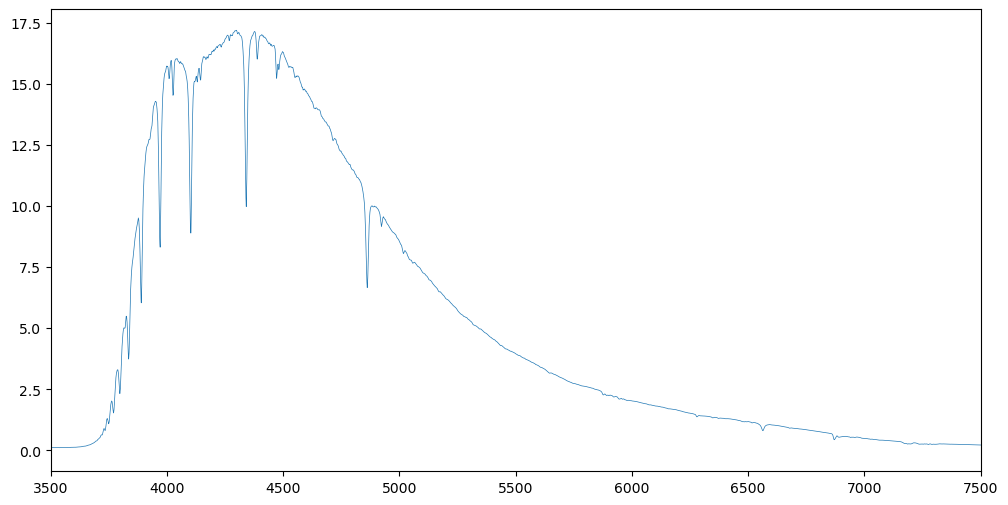

In [7]:
plt.figure(figsize=(12,6))
plt.plot(wl, flux, lw=0.5)
#plt.ylim(ymin, ymax)
plt.xlim(3500,7500)
plt.show()

## Continuum related procedures

In [8]:
def robust_continuum_fit(x, y, exclude_windows, degree, sigma_lo=3.0, sigma_hi=3.0, max_iter=20):
    seed = np.ones(len(x), dtype=bool)
    for lo, hi in exclude_windows:
        seed &= ~((x >= lo) & (x <= hi))
    xc = x - x.mean()
    mask = seed.copy()
    for i in range(max_iter):
        p = np.polyfit(xc[mask], y[mask], degree)
        resid = y - np.polyval(p, xc)
        s = resid[mask].std()
        new_mask = seed & (resid > -sigma_lo * s) & (resid < sigma_hi * s)
        if np.array_equal(new_mask, mask):
            break
        mask = new_mask
    return p, x.mean(), mask

In [9]:
def rectify_zone(wl, flux, zone, plot=False, degree=7, max_iter=20, sigma_lo=1.5, sigma_hi=10.0):
    zone_min, zone_max = zone
    enlarged_zone_min = zone_min - 50
    enlarged_zone_max = zone_max + 50

    mw = (wl >= enlarged_zone_min) & (wl <= enlarged_zone_max)
    p, wlmean, mask = robust_continuum_fit(wl[mw], flux[mw], EXCLUDED_REGIONS, degree, max_iter=max_iter, sigma_lo=sigma_lo, sigma_hi=sigma_hi)
    cont = np.polyval(p, wl - wlmean)[mw]

    if plot:
        plt.figure(figsize=(12,6))
        plt.plot(wl[mw], flux[mw], lw=0.5)
        plt.plot(wl[mw], cont, lw=0.5)
        #plt.ylim(ymin, ymax)
        plt.xlim(enlarged_zone_min,enlarged_zone_max)
        plt.title("Continuum fit")
        plt.show()    

    rect3 = flux[mw] / cont
    wl3 = wl[mw]
    mw = (wl3 >= zone_min) & (wl3 <= zone_max)
    rect3 = rect3[mw]
    wl3 = wl3[mw]  

    if plot:
        plt.figure(figsize=(12,6))
        plt.plot(wl3, rect3, lw=0.5)
        #plt.ylim(0.7, 1.05)
        plt.xlim(enlarged_zone_min,enlarged_zone_max)
        plt.title("Continuum calibrated spectrum")
        plt.show()

    return wl3, rect3

## Noise evaluation

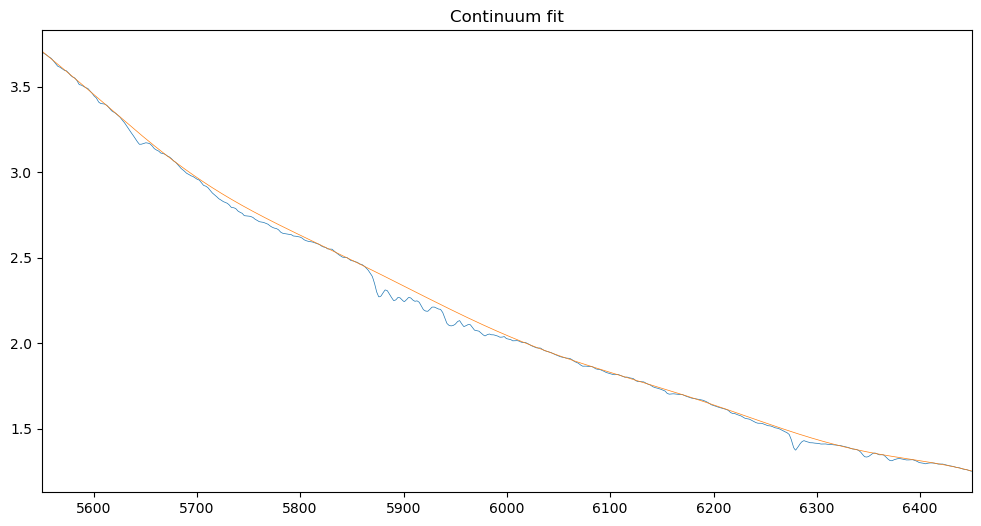

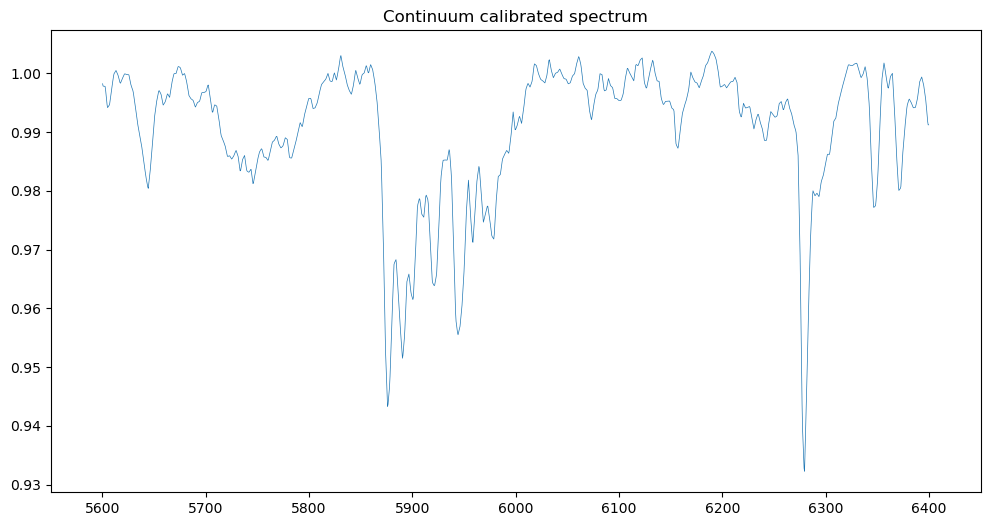

Noise =  0.002919931863023589 Flux at eval window =  2.6893357038497925 SNR =  921.0268698068131


In [10]:
continuum_mask = (wl > NOISE_CONTINUUM_WINDOW[0]) & (wl < NOISE_CONTINUUM_WINDOW[1])
wlzone, rectzone = rectify_zone(wl, flux, NOISE_CONTINUUM_WINDOW, degree=NOISE_CONTINUUM_DEGREE, plot=True)
evaluation_mask = (wlzone > NOISE_EVALUATION_WINDOW[0]) & (wlzone < NOISE_EVALUATION_WINDOW[1])
noise = 1.4826 * np.median(
        np.abs(rectzone[evaluation_mask] - np.median(rectzone[evaluation_mask]))
    )
noise_evaluation_flux = np.median(flux[continuum_mask][evaluation_mask])
snr = noise_evaluation_flux / noise
print("Noise = ",noise, "Flux at eval window = ", noise_evaluation_flux, "SNR = ", snr)

## Line Fitting procedures

In [11]:
def gaussian_model(x, amp, mu, sigma, offset):
    return amp * np.exp(-0.5 * ((x - mu) / sigma) ** 2) + offset
    
    

def voigt_model(x, amp, mean, sigma, gamma, offset):
    # voigt_profile(x - mean, sigma, gamma) è normalizzata a area = 1
    return amp * voigt_profile(x - mean, sigma, gamma) + offset

In [12]:
def plot_gauss_fit(w, f, popt, name):
    plt.figure(figsize=(6,4))
    plt.plot(w, f, "k", label="Data")
    plt.plot(w, gaussian_model(w, *popt), "r", label="Gaussian fit")
    plt.legend()
    plt.xlabel("Wavelength")
    plt.title(name)
    plt.show()

In [13]:
def calc_gaussian_chi2(w, f, amp, mu, sigma, offset, fwhm):
    wl_min = mu - fwhm
    wl_max = mu + fwhm
    mask = (w > wl_min) & (w < wl_max)
    res_w = w[mask]
    res_f = f[mask]
    return (((res_f - gaussian_model(res_w, amp, mu, sigma, offset)) ** 2)/gaussian_model(res_w, amp, mu, sigma, offset)).sum()

In [14]:
def fit_line_gaussian(wavelength, flux, lam_expected, fwhm_expected, plot=False, name=""):    
    peak_idx = np.argmin(np.abs(wavelength - lam_expected))
    amp0 = max(1.0 - flux[peak_idx], 0.0)
    offset = 1.0
    #p0 = [-amp0, lam_expected, fwhm_expected / 2.355, median_continuum]
    p0 = [-amp0, lam_expected, fwhm_expected / 2.355]
    #if plot:
    #    print("initial guess", p0)
    fit_wl_min = lam_expected - GAUSS_FIT_WINDOW * fwhm_expected
    fit_wl_max = lam_expected + GAUSS_FIT_WINDOW * fwhm_expected
    fit_window_mask = (wavelength > fit_wl_min) & (wavelength < fit_wl_max) 
    w = wavelength[fit_window_mask]
    f = flux[fit_window_mask]
    try:
        # popt, _ = curve_fit(gaussian_model, w, f, p0=p0)
        bounds_lo = [ GAUSS_AMP_MIN * amp0, lam_expected - GAUSS_LAMBDA_WIN, GAUSS_SIGMA_MIN * fwhm_expected / 2.355]
        bounds_hi = [ GAUSS_AMP_MAX * amp0, lam_expected + GAUSS_LAMBDA_WIN, GAUSS_SIGMA_MAX * fwhm_expected / 2.355]
        popt, _ = curve_fit(
            lambda x, a, m, s: gaussian_model(x, a, m, s, offset),
            w,
            f,
            p0 = p0,
            bounds = (bounds_lo, bounds_hi))
        #amp, mu, sigma, offset = popt
        amp, mu, sigma = popt
            
        sigma_nom = abs(sigma)
        fwhm_fit = 2.355 * sigma_nom
        fwhm_nom = fwhm_fit #np.clip(fwhm_fit, 0.7 * fwhm_instr, 1.5 * fwhm_instr)
        ew_nom = np.sqrt(2 * np.pi) * abs(amp) * sigma_nom / offset

        chi2 = calc_gaussian_chi2(w, f, amp, mu, sigma, offset, fwhm_nom)
        
        if plot:
            print("amp =",amp,"\nmu =",mu,"\nsigma =",sigma,"\noffset =",offset,"\nchi2 = ",chi2)
            plot_mask = (w >= mu-GAUSSIAN_FIT_PLOT_WINDOW*fwhm_nom) & (w <= mu+GAUSSIAN_FIT_PLOT_WINDOW*fwhm_nom)
            plot_gauss_fit(w[plot_mask], f[plot_mask], (amp, mu, sigma, offset), name)
    except RuntimeError:
        fwhm_nom = np.nan
        ew_nom = np.nan
        mu = np.nan
        amp = np.nan
        chi2 = np.nan

    return (mu, ew_nom, fwhm_nom, amp, chi2)

In [15]:
def plot_voigt_fit(w, f, popt, name):
    plt.figure(figsize=(6,4))
    plt.plot(w, f, "k", label="Data")
    plt.plot(w, voigt_model(w, *popt), "r", label="Voigt fit")
    plt.legend()
    plt.xlabel("Wavelength")
    plt.title(name)
    plt.show()

In [16]:
def calc_voigt_chi2(w, f, amp, mu, sigma, gam, offset, fwhm):
    wl_min = mu - 2 * fwhm
    wl_max = mu + 2 * fwhm
    mask = (w > wl_min) & (w < wl_max)
    res_w = w[mask]
    res_f = f[mask]
    return (((res_f - voigt_model(res_w, amp, mu, sigma, gam, offset))**2)/voigt_model(res_w, amp, mu, sigma, gam, offset)).sum()

In [17]:
def fit_line_voigt(wavelength, flux, lam_expected, fwhm_expected, plot=False, name=""):
    
    peak_idx = np.argmin(np.abs(wavelength - lam_expected))
    amp0 = max(1.0 - flux[peak_idx], 0.0)
    offset = 1.0
    p0 = [-amp0, lam_expected, fwhm_expected / 2.355, fwhm_expected / 2.355]
    #p0 = [-amp0, lam_expected, fwhm_expected / 2.355, fwhm_expected / 2.355, offset]
    fit_wl_min = lam_expected - VOIGT_FIT_WINDOW * fwhm_expected
    fit_wl_max = lam_expected + VOIGT_FIT_WINDOW * fwhm_expected
    fit_window_mask = (wavelength > fit_wl_min) & (wavelength < fit_wl_max) 
    w = wavelength[fit_window_mask]
    f = flux[fit_window_mask]
    #if plot:
    #    print("initial guess", p0)
    try:
        #popt, _ = curve_fit(voigt_model, w, f, p0=p0)
        popt, _ = curve_fit(
            lambda x, a, m, s, g: voigt_model(x, a, m, s, g, offset),
            w,
            f,
            p0 = p0)
        #amp, mu, sigma, gam, offset = popt
        amp, mu, sigma, gam = popt
        #sigma_nom = abs(sigma)

        intensity = amp * voigt_profile(0.0, sigma, gam)
        
        f_g = 2 * sigma * np.sqrt(2 * np.log(2))
        f_l = 2 * gam
        fwhm_nom = 0.5346 * f_l + np.sqrt(0.2166 * f_l**2 + f_g**2)
        
        ew_nom = abs(amp)/offset

        chi2 = calc_voigt_chi2(w, f, amp, mu, sigma, gam, offset, fwhm_nom)
        
        if plot:
            print("amp =",amp,"\nmu =",mu,"\nsigma =",sigma,"\ngamma =",gam,"\noffset =",offset,"\nchi2 =",chi2)
            plot_mask = (w >= mu-VOIGT_FIT_PLOT_WINDOW*fwhm_nom) & (w <= mu+VOIGT_FIT_PLOT_WINDOW*fwhm_nom)
            plot_voigt_fit(w[plot_mask], f[plot_mask], (amp, mu, sigma, gam, offset), name)
    except RuntimeError:
        fwhm_nom = np.nan
        ew_nom = np.nan
        mu = np.nan
        intensity = np.nan
        chi2 = np.nan

    return (mu, ew_nom, fwhm_nom, intensity, chi2)

In [18]:
# Number of fit parameters used by each component model:
#   gauss : amp (line depth), mu, sigma
#   voigt : amp (area),       mu, sigma, gamma
PARAMS_PER_MODEL = {"gauss": 3, "voigt": 4}


def normalize_model_name(line):
    """Return 'gauss' or 'voigt' for a blend component dict (default: 'gauss')."""
    model = str(line.get("model", "gauss")).strip().lower()
    if model in ("gauss", "gaussian"):
        return "gauss"
    if model == "voigt":
        return "voigt"
    raise ValueError(f"Unknown model '{line.get('model')}' for blend component "
                     f"'{line.get('name')}': use 'gauss' or 'voigt'")


def voigt_fwhm(sigma, gamma):
    # Olivero & Longbothum approximation (same formula used by fit_line_voigt)
    f_g = 2 * sigma * np.sqrt(2 * np.log(2))
    f_l = 2 * gamma
    return 0.5346 * f_l + np.sqrt(0.2166 * f_l**2 + f_g**2)


def component_profile(x, model, params):
    """Profile of a single blend component, WITHOUT the continuum offset."""
    if model == "voigt":
        amp, mu, sigma, gamma = params
        return amp * voigt_profile(x - mu, sigma, gamma)
    amp, mu, sigma = params
    return amp * np.exp(-0.5 * ((x - mu) / sigma) ** 2)


def split_blend_params(models, params):
    """Split the flat parameter vector into one tuple per component."""
    result = []
    k = 0
    for model in models:
        n = PARAMS_PER_MODEL[model]
        result.append(tuple(params[k:k + n]))
        k += n
    return result


def multi_line_model(x, offset, models, *params):
    """Sum of gaussian / voigt components (one entry of `models` per component) + continuum."""
    model = np.zeros_like(x, dtype=float)
    for m, p in zip(models, split_blend_params(models, params)):
        model += component_profile(x, m, p)
    return model + offset

In [19]:
def multi_line_initial_guess(lines, wavelength, flux):
    """Initial guess and bounds for a blend of gaussian / voigt components.

    `lines` is the list of component dicts ("wavelength" and optionally "model").
    """
    p0 = []
    bounds_lo = []
    bounds_hi = []
    for line in lines:
        model = normalize_model_name(line)
        lam0 = line["wavelength"]
        peak_index = np.argmin(np.abs(wavelength - lam0))
        depth0 = min(flux[peak_index] - 1.0, 0.0)
        fwhm_instr = lam0 / INSTR_RESOLUTION
        sigma_instr = fwhm_instr / 2.355

        if model == "gauss":
            p0 += [depth0, lam0, sigma_instr]
            bounds_lo += [GAUSS_AMP_MIN, lam0 - GAUSS_LAMBDA_WIN, GAUSS_SIGMA_MIN * sigma_instr]
            bounds_hi += [GAUSS_AMP_MAX, lam0 + GAUSS_LAMBDA_WIN, GAUSS_SIGMA_MAX * sigma_instr]
        else:
            # Voigt amplitude is the (normalised) area, i.e. -EW for a continuum of 1.
            # Convert the observed depth to an area using the starting profile shape.
            gamma0 = 0.5 * sigma_instr
            amp0 = depth0 / voigt_profile(0.0, sigma_instr, gamma0)
            # Same limits as the gaussian, expressed as areas (depth * width)
            area_scale = np.sqrt(2 * np.pi) * 4.0 * sigma_instr
            amp_lo, amp_hi = -1.5 * area_scale, 0.5 * area_scale
            p0 += [float(np.clip(amp0, amp_lo, amp_hi)), lam0, sigma_instr, gamma0]
            bounds_lo += [amp_lo, lam0 - VOIGT_LAMBDA_WIN, VOIGT_SIGMA_MIN * sigma_instr, 0.0]
            bounds_hi += [amp_hi, lam0 + VOIGT_LAMBDA_WIN, VOIGT_SIGMA_MAX * sigma_instr, VOIGT_GAMMA_MAX * sigma_instr]

    return (p0, bounds_lo, bounds_hi)

In [20]:
def plot_multi_line_fit(w, f, popt, models, component, name):
    """Plot data, total blend fit and the component called `name`.

    `component` is the (model, params) pair of the component to highlight.
    """
    comp_model, comp_params = component
    plt.figure(figsize=(6,4))
    plt.plot(w, f, "k", label="Data")
    plt.plot(w, multi_line_model(w, 1.0, models, *popt), "r", label="Blend fit")
    plt.plot(w, component_profile(w, comp_model, comp_params) + 1.0, "y",
             label=f"{name} ({comp_model})")
    plt.legend()
    plt.xlabel("Wavelength")
    plt.title(name)
    plt.show()

In [21]:
def blend_initial_fwhm(line):
    """FWHM assumed only for the FIRST pass, before any fit exists.
    gauss: instrumental FWHM. voigt: widest profile the fit bounds allow (generous first window)."""
    sigma_instr = line["wavelength"] / INSTR_RESOLUTION / 2.355
    if normalize_model_name(line) == "voigt":
        return voigt_fwhm(VOIGT_SIGMA_MAX * sigma_instr, VOIGT_GAMMA_MAX * sigma_instr)
    return 2.355 * sigma_instr


def blend_fit_window(lines, fwhms, limits=None):
    """margin = max(span margin, BLEND_FWHM_MARGIN * max(fwhms)), applied on both sides of the outermost components."""
    lams = [l["wavelength"] for l in lines]
    lam_min, lam_max = min(lams), max(lams)
    margin = max(BLEND_SPAN_MARGIN_FACTOR * (lam_max - lam_min), BLEND_FWHM_MARGIN * max(fwhms))
    lo, hi = lam_min - margin, lam_max + margin
    if limits is not None:
        lo, hi = max(lo, limits[0]), min(hi, limits[1])
    return lo, hi


def fit_blend_adaptive(wavelength, flux, lines, limits=None):
    """Fit, rebuild the window from the fitted FWHMs, refit until the window is stable.
    Returns (results, window). `limits` = (lo, hi) range that must never be exceeded."""
    window = blend_fit_window(lines, [blend_initial_fwhm(l) for l in lines], limits)
    results = None
    for _ in range(BLEND_WINDOW_MAX_ITER):
        try:
            new_results = fit_blend_group(wavelength, flux, lines, fit_window=window)
        except RuntimeError:
            if results is None:
                raise
            break                      # keep the last window that worked
        results = new_results
        ews = np.array([r[2] for r in results])
        fwhms = np.array([r[3] for r in results])
        significant = ews >= BLEND_MIN_EW_FRACTION * ews.max()
        new_window = blend_fit_window(lines, fwhms[significant], limits)
        converged = max(abs(new_window[0] - window[0]), abs(new_window[1] - window[1])) < BLEND_WINDOW_TOL
        window = new_window
        if converged:
            break
    return results, window

In [22]:
def fit_blend_group(wavelength, flux, lines, plot=False, fit_window=None):
    models = [normalize_model_name(l) for l in lines]
    if fit_window is None:   # fallback when called without a precomputed window
        fit_window = blend_fit_window(lines, [blend_initial_fwhm(l) for l in lines])
    wl_min, wl_max = fit_window
    
    mask = (wavelength > wl_min) & (wavelength < wl_max)
    
    w = wavelength[mask]
    f = flux[mask]
    offset = 1.0
    
    p0, bounds_lo, bounds_hi = multi_line_initial_guess(lines, w, f)
    
    popt, _ = curve_fit(
            lambda x, *params: multi_line_model(x, offset, models, *params),
            w,
            f,
            p0 = p0,
            bounds = (bounds_lo, bounds_hi))
    
    # One parameter tuple per component (3 values for gauss, 4 for voigt)
    component_results = split_blend_params(models, popt)

    chi2 = (((multi_line_model(w, offset, models, *popt) - f) ** 2)/multi_line_model(w, offset, models, *popt)).sum()
    
    final_results = []
    
    for line, model, params in zip(lines, models, component_results):
        if model == "voigt":
            amp, mu, sigma, gam = params
            fwhm_nom = voigt_fwhm(sigma, gam)
            ew_nom = abs(amp) / offset
            intensity = amp * voigt_profile(0.0, sigma, gam)
        else:
            amp, mu, sigma = params
            fwhm_nom = 2.355 * abs(sigma)
            ew_nom = np.sqrt(2 * np.pi) * abs(amp) * abs(sigma) / offset
            intensity = amp
        
        final_results.append((line["name"], mu, ew_nom, fwhm_nom, intensity, chi2))
        
        if plot:
            print(line["name"], f"({model})")
            if model == "voigt":
                print("amp =",amp,"\nmu =",mu,"\nsigma =",sigma,"\ngamma =",gam,"\noffset =",offset,"\nchi2 =",chi2)
            else:
                print("amp =",amp,"\nmu =",mu,"\nsigma =",sigma,"\noffset =",offset,"\nchi2 =",chi2)
            plot_multi_line_fit(w, f, popt, models, (model, params), line["name"])
        
    return final_results

## Functions for error on continuum placement

In [23]:
# ---------------------------------------------------------------- configuration
N_JOBS  = max(1, (os.cpu_count() or 2) - 2)   # worker processes; leave 2 logical CPUs free
MC_SEED = None                                 # set e.g. to 12345 for reproducible Monte Carlo runs


# ---------------------------------------------------------------- helpers
def _draw_trials(rng, n, sigma_lo_range, sigma_hi_range, degree_range, maxiter_range, winlo_range, winhi_range):
    """Draw all the random continuum parameters up front (same distributions as before)."""
    trials = []
    for i in range(1, n):                       # same count as the original loop
        trials.append(dict(
            i=i,
            sigma_lo=float(rng.uniform(*sigma_lo_range)),
            sigma_hi=float(rng.uniform(*sigma_hi_range)),
            degree=int(rng.integers(*degree_range)),
            maxiter=int(rng.integers(*maxiter_range)),
            win_lo=float(rng.uniform(*winlo_range)),
            win_hi=float(rng.uniform(*winhi_range)),
            seed=int(rng.integers(0, 2**63 - 1)),   # private seed for this trial's noise
        ))
    return trials


def _rectify_trial(wl, flux, t, add_noise, noise, noise_evaluation_flux):
    win = (t["win_lo"], t["win_hi"])
    if add_noise:
        win_mask = (wl > win[0]) & (wl < win[1])
        rescaled_noise = noise * np.sqrt(np.median(flux[win_mask]) * noise_evaluation_flux)
        flux = flux + np.random.default_rng(t["seed"]).normal(0, rescaled_noise, size=len(flux))
    return rectify_zone(wl, flux, win, plot=False, sigma_lo=t["sigma_lo"], sigma_hi=t["sigma_hi"],
                        degree=t["degree"], max_iter=t["maxiter"])


def _run_parallel(chunk_worker, trials, **common):
    """Split the trials in chunks (so the spectrum is shipped once per chunk, not once per trial),
    run them on N_JOBS processes, and return (records, errors)."""
    if N_JOBS == 1:
        outs = [chunk_worker(trials, **common)]
    else:
        n_chunks = min(len(trials), N_JOBS * 4)          # a few chunks per worker -> good load balancing
        chunks = [list(c) for c in np.array_split(np.array(trials, dtype=object), n_chunks)]
        outs = Parallel(n_jobs=N_JOBS)(delayed(chunk_worker)(c, **common) for c in chunks)
    records = [r for o in outs for r in o[0]]
    errors  = [e for o in outs for e in o[1]]
    if errors:
        print(f"{len(errors)} trials failed; first error: {errors[0]}")
    return records, errors

In [24]:
def _single_line_chunk(trials, wl, flux, model, expected_lam, expected_width, add_noise, noise, noise_evaluation_flux):
    records, errors = [], []
    for t in trials:
        try:
            wlzone, rectzone = _rectify_trial(wl, flux, t, add_noise, noise, noise_evaluation_flux)
            if model == "voigt":
                lam, ew, fwhm, amp, chi2 = fit_line_voigt(wlzone, rectzone, expected_lam, expected_width, plot=False)
            else:
                lam, ew, fwhm, amp, chi2 = fit_line_gaussian(wlzone, rectzone, expected_lam, expected_width, plot=False)
            records.append({"sigma_lo": t["sigma_lo"], "sigma_hi": t["sigma_hi"], "degree": t["degree"],
                            "maxiter": t["maxiter"], "win_lo": t["win_lo"], "win_hi": t["win_hi"],
                            "wavelength": lam, "ew": ew, "fwhm": fwhm, "intensity": amp, "chi2": chi2})
        except Exception as e:
            errors.append(repr(e))
    return records, errors

def remove_worst_fits_from_results(results):
    removed = 100
    while removed > 0:
        m_res = results["chi2"].mean()
        s_res = results["chi2"].std()
        filtered_results = results[(results["chi2"]-m_res).abs() <= WORST_FIT_SIGMA_TO_REMOVE*s_res]
        removed = len(results) - len(filtered_results)
        # print(f"Removed {removed}")
        results = filtered_results
    return results

def fit_varying_continuum(wl, flux, model, expected_lam, expected_width, add_noise=False, noise=0.0, noise_evaluation_flux=1.0, sigma_lo_range=(1.5,2.0), sigma_hi_range=(9.9,10.1), degree_range=(6,14), maxiter_range=(10,30), winlo_range=None, winhi_range=None):
    rng = np.random.default_rng(MC_SEED)
    trials = _draw_trials(rng, MONTECARLO_SAMPLES, sigma_lo_range, sigma_hi_range, degree_range, maxiter_range, winlo_range, winhi_range)
    records, _ = _run_parallel(_single_line_chunk, trials, wl=wl, flux=flux, model=model,
                               expected_lam=expected_lam, expected_width=expected_width,
                               add_noise=add_noise, noise=noise, noise_evaluation_flux=noise_evaluation_flux)
    cols = ["sigma_lo","sigma_hi","degree","maxiter","win_lo","win_hi","wavelength","ew","fwhm","intensity","chi2"]
    results = pd.DataFrame(records, columns=cols)

    if REMOVE_WORST_FITS:
        results = remove_worst_fits_from_results(results)

    m = results["ew"].mean()
    results["ew_dist"] = abs(results["ew"] - m)
    
    return results

In [25]:
def refit_with_best(column, results, wl, flux, model, expected_lam, expected_width, plot=False, name=""):
    sort_col = column + "_dist"
    sorted_results = results.sort_values(by=[sort_col], ascending=True)
    best = sorted_results.iloc[0]
    sigma_lo = best["sigma_lo"]
    sigma_hi = best["sigma_hi"]
    degree = int(best["degree"])
    maxiter = int(best["maxiter"])
    win = (best["win_lo"], best["win_hi"])
    wlzone, rectzone = rectify_zone(wl, flux, win, plot=plot, sigma_lo=sigma_lo, sigma_hi=sigma_hi, degree=degree, max_iter=maxiter)
    if (model == "voigt"):
        lam, ew, fwhm, amp, chi2 = fit_line_voigt(wlzone, rectzone, expected_lam, expected_width, plot=plot, name=name)
    else:
        lam, ew, fwhm, amp, chi2 = fit_line_gaussian(wlzone, rectzone, expected_lam, expected_width, plot=plot, name=name)
    return (lam, ew, fwhm, amp)

In [26]:
def _blend_chunk(trials, wl, flux, blended_lines, fit_window, add_noise, noise, noise_evaluation_flux):
    records, errors = [], []
    for t in trials:
        try:
            wlzone, rectzone = _rectify_trial(wl, flux, t, add_noise, noise, noise_evaluation_flux)
            blend_results = fit_blend_group(wlzone, rectzone, blended_lines, plot=False, fit_window=fit_window)
            for name, lam_detected, ew, fwhm, amp, chi2 in blend_results:
                records.append({"sigma_lo": t["sigma_lo"], "sigma_hi": t["sigma_hi"], "degree": t["degree"],
                                "maxiter": t["maxiter"], "win_lo": t["win_lo"], "win_hi": t["win_hi"],
                                "record": t["i"], "line": name, "wavelength": lam_detected, "ew": ew,
                                "fwhm": fwhm, "intensity": amp, "chi2": chi2})
        except Exception as e:
            errors.append(repr(e))
    return records, errors


def fit_blend_varying_continuum(wl, flux, blended_lines, add_noise=False, noise=0.0, noise_evaluation_flux=1.0, sigma_lo_range=(1.5,2.0), sigma_hi_range=(9.9,10.1), degree_range=(6,14), maxiter_range=(10,30), winlo_range=None, winhi_range=None, fit_window=None):
    rng = np.random.default_rng(MC_SEED)
    trials = _draw_trials(rng, MONTECARLO_SAMPLES, sigma_lo_range, sigma_hi_range, degree_range, maxiter_range, winlo_range, winhi_range)
    records, _ = _run_parallel(_blend_chunk, trials, wl=wl, flux=flux, blended_lines=blended_lines,
                               fit_window=fit_window, add_noise=add_noise, noise=noise,
                               noise_evaluation_flux=noise_evaluation_flux)
    cols = ["sigma_lo","sigma_hi","degree","maxiter","win_lo","win_hi","record","line","wavelength","ew","fwhm","intensity","chi2"]
    results = pd.DataFrame(records, columns=cols)

    if REMOVE_WORST_FITS:
        results = remove_worst_fits_from_results(results)

    results["ew_dist"] = (results["ew"] - results.groupby("line")["ew"].transform("mean")).abs()
    results["ew_dist_ssq"] = (results["ew_dist"]**2).groupby(results["record"]).transform("sum")

    return results

In [27]:
def refit_blend_with_best(column, results, wl, flux, blended_lines, expected_width, plot=False, name="", fit_window=None):
    sort_col = column + "_dist_ssq"
    sorted_results = results.sort_values(by=[sort_col], ascending=True)
    best = sorted_results.iloc[0]
    sigma_lo = best["sigma_lo"]
    sigma_hi = best["sigma_hi"]
    degree = int(best["degree"])
    maxiter = int(best["maxiter"])
    win = (best["win_lo"], best["win_hi"])
    wlzone, rectzone = rectify_zone(wl, flux, win, plot=True, sigma_lo=sigma_lo, sigma_hi=sigma_hi, degree=degree, max_iter=maxiter)
    blend_results = fit_blend_group(wlzone, rectzone, blended_lines, plot=True, fit_window=fit_window)

## Complete measure procedures

In [28]:
def round_measurement(value, error):
    exponent = math.floor(math.log10(error))
    first_digit = int(error / (10 ** exponent))

    sig_figs = 2 if first_digit in (1,2) else 1

    decimals = sig_figs - exponent - 1

    value_rounded = round (value, decimals)
    error_rounded = round(error, decimals)

    return value_rounded, error_rounded

In [29]:
from IPython.display import Markdown
from IPython.display import display

def measure_line(wl, flux, measuring_line, show_param_dependencies=False):
    name = measuring_line["name"]
    
    display(Markdown(f"### Measuring {name}"))
    model = measuring_line["model"]
    central_wl = measuring_line["central_wl"]
    winlo_range = measuring_line["winlo_range"]
    winhi_range = measuring_line["winhi_range"]
    
    display(Markdown(f"#### {name} preliminary fit"))
    rect_win = (winlo_range[1], winhi_range[0])
    wlzone, rectzone = rectify_zone(wl, flux, rect_win, plot=True)
    if model == "voigt":
        lam, ew, fwhm, amp, chi2 = fit_line_voigt(wlzone, rectzone, central_wl, 5.0, plot=True, name=name)
    else:
        lam, ew, fwhm, amp, chi2 = fit_line_gaussian(wlzone, rectzone, central_wl, 5.0, plot=True, name=name)
    print("Lambda = ", lam, "Eq Width =", ew, "FWHM = ", fwhm, "Intensity = ", amp)
    
    display(Markdown(f"#### {name} optimization"))
    results = fit_varying_continuum(wl, flux, model, central_wl, fwhm, winlo_range=winlo_range, winhi_range=winhi_range, degree_range=DEGREE_RANGE, sigma_lo_range=SIGMALO_RANGE, sigma_hi_range=SIGMAHI_RANGE, add_noise=ADD_NOISE, noise=noise, noise_evaluation_flux=noise_evaluation_flux)

    fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(12,6))
    plt.subplots_adjust(wspace=0.5, hspace=0.5)
    
    m_ew = results["ew"].mean()
    s_ew = results["ew"].std()
    results.plot.hist(column=["ew"], title="EW mean=%g std dev=%g" % round_measurement(m_ew,s_ew), ax=axes[0,0])
    
    m_fwhm = results["fwhm"].mean()
    s_fwhm = results["fwhm"].std()
    results.plot.hist(column=["fwhm"], title="FWHM mean=%g std dev=%g" % round_measurement(m_fwhm,s_fwhm), ax=axes[0,1])
    
    m_wl = results["wavelength"].mean()
    s_wl = results["wavelength"].std()
    results.plot.hist(column=["wavelength"], title="Central wavelength mean=%g std dev=%g" % round_measurement(m_wl,s_wl), ax=axes[1,0])
    
    m_amp = results["intensity"].mean()
    s_amp = results["intensity"].std()
    results.plot.hist(column=["intensity"], title="Intensity mean=%g std dev=%g" % round_measurement(m_amp,s_amp), ax=axes[1,1])
    
    plt.show()

    display(Markdown(f"#### {name} re-fit with best parameters"))
    lam, ew, fwhm, amp = refit_with_best("ew", results, wl, flux, model, central_wl, m_fwhm, plot=True, name=name)
    print("Lambda = ", lam, "Eq Width =", ew, "FWHM = ", fwhm, "Intensity = ", amp)

    if show_param_dependencies:
        display(Markdown(f"#### {name} continuum parameters dependencies"))
        results["win_size"] = results["win_hi"] - results["win_lo"]
        results["dist"] = abs(results["ew"] - m_ew)

        results.plot.hist(column=["chi2"], figsize=(12,6), title="Chi quadro")
        
        sorted_results = results.sort_values(by=["dist"], ascending=True)
        sorted_results.plot(x="dist", y="sigma_lo", ylim=(0,6))
        sorted_results.plot(x="dist", y="degree", ylim=(2,15))
        sorted_results.plot(x="dist", y="maxiter", ylim=(8,32))
        sorted_results.plot(x="dist", y="win_size", ylim=(400,800))
        
        results.sort_values(by=["sigma_lo"], ascending=True).plot(x="sigma_lo", y="dist", ylim=(0,8))
        results.sort_values(by=["win_size"], ascending=True).plot(x="win_size", y="dist", ylim=(0,8))
        
        sorted_results.plot.scatter(x="degree", y="win_size", c="dist")
        sorted_results.plot.scatter(x="win_lo", y="win_hi", c="dist")
        plt.show()
    
    return pd.Series({"line_name":name, "wavelength":m_wl, "delta_wavelength":s_wl, "ew":m_ew, "delta_ew":s_ew, "fwhm":m_fwhm, "delta_fwhm":s_fwhm, "intensity": m_amp, "delta_intensity": s_amp})

In [30]:
def measure_blend(wl, flux, measuring_blend, show_param_dependencies=False):
    name = measuring_blend["name"]
    
    display(Markdown(f"### Measuring {name}"))
    blended_lines = measuring_blend["central_wls"]
    winlo_range = measuring_blend["winlo_range"]
    winhi_range = measuring_blend["winhi_range"]
    print("Blended lines=", blended_lines)
    display(Markdown(f"#### {name} preliminary fit"))
    rect_win = (winlo_range[1], winhi_range[0])
    wlzone, rectzone = rectify_zone(wl, flux, rect_win, plot=True)
    prelim_results, fit_window = fit_blend_adaptive(wlzone, rectzone, blended_lines, limits=rect_win)
    print("Fit window = (%.1f, %.1f)" % fit_window)
    fit_blend_group(wlzone, rectzone, blended_lines, plot=True, fit_window=fit_window)
    
    display(Markdown(f"#### {name} optimization"))
    results = fit_blend_varying_continuum(wl, flux, blended_lines, degree_range=DEGREE_RANGE, sigma_lo_range=SIGMALO_RANGE, sigma_hi_range=SIGMAHI_RANGE, add_noise=ADD_NOISE, noise=noise, noise_evaluation_flux=noise_evaluation_flux, winlo_range=winlo_range, winhi_range=winhi_range, fit_window=fit_window)

    blend_results = pd.DataFrame(columns=("line_name","wavelength","delta_wavelength","ew","delta_ew","fwhm","delta_fwhm","intensity","delta_intensity"))
    i = 0
    for line in blended_lines:
        line_name = line["name"]
        display(Markdown(f"#### Plotting results for {line_name}"))
        line_results = results[results["line"] == line["name"]]

        fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(12,6))
        plt.subplots_adjust(wspace=0.5, hspace=0.5)
        
        m_ew = line_results["ew"].mean()
        s_ew = line_results["ew"].std()
        line_results.plot.hist(column=["ew"], figsize=(12,6), title="EW mean=%g std dev=%g" % round_measurement(m_ew,s_ew), ax=axes[0,0])
    
        m_fwhm = line_results["fwhm"].mean()
        s_fwhm = line_results["fwhm"].std()
        line_results.plot.hist(column=["fwhm"], figsize=(12,6), title="FWHM mean=%g std dev=%g" % round_measurement(m_fwhm,s_fwhm), ax=axes[0,1])
        
        m_wl = line_results["wavelength"].mean()
        s_wl = line_results["wavelength"].std()
        line_results.plot.hist(column=["wavelength"], figsize=(12,6), title="Central wavelength mean=%g std dev=%g" % round_measurement(m_wl,s_wl), ax=axes[1,0])

        m_amp = line_results["intensity"].mean()
        s_amp = line_results["intensity"].std()
        line_results.plot.hist(column=["intensity"], figsize=(12,6), title="Intensity mean=%g std dev=%g" % round_measurement(m_amp,s_amp), ax=axes[1,1])
        plt.show()
    
        # print("Mean:", m_ew)
        # print("Std Dev:",s_ew)

        line_results = pd.Series({"line_name":line_name, "wavelength":m_wl, "delta_wavelength":s_wl, "ew":m_ew, "delta_ew":s_ew, "fwhm":m_fwhm, "delta_fwhm":s_fwhm, "intensity":m_amp, "delta_intensity":s_amp})
        blend_results.loc[i] = line_results
        i = i + 1

    display(Markdown(f"#### {name} re-fit with best parameters"))
    refit_blend_with_best("ew", results, wl, flux, blended_lines, m_fwhm, plot=True, name=name, fit_window=fit_window)

    if show_param_dependencies:
        display(Markdown(f"#### {name} continuum parameters dependencies"))

        results.plot.hist(column=["chi2"], figsize=(12,6), title="Chi quadro")
        
        for line in blended_lines:
            print("Plotting results for ",line["name"])
            line_results = results[results["line"] == line["name"]]
        
            m = line_results["ew"].mean()
            
            line_results["win_size"] = line_results["win_hi"] - line_results["win_lo"]
            line_results["dist"] = abs(line_results["ew"] - m)
            
            sorted_results = line_results.sort_values(by=["dist"], ascending=True)
            sorted_results.plot(x="dist", y="sigma_lo", ylim=(0,6))
            sorted_results.plot(x="dist", y="degree", ylim=(2,15))
            sorted_results.plot(x="dist", y="maxiter", ylim=(8,32))
            sorted_results.plot(x="dist", y="win_size", ylim=(250,800))
            
            line_results.sort_values(by=["sigma_lo"], ascending=True).plot(x="sigma_lo", y="dist", ylim=(0,8))
            line_results.sort_values(by=["win_size"], ascending=True).plot(x="win_size", y="dist", ylim=(0,8))
            
            sorted_results.plot.scatter(x="degree", y="win_size", c="dist")
            sorted_results.plot.scatter(x="win_lo", y="win_hi", c="dist")
            plt.show()
            
    return blend_results

## Measure All Lines

### Measuring H alfa

#### H alfa preliminary fit

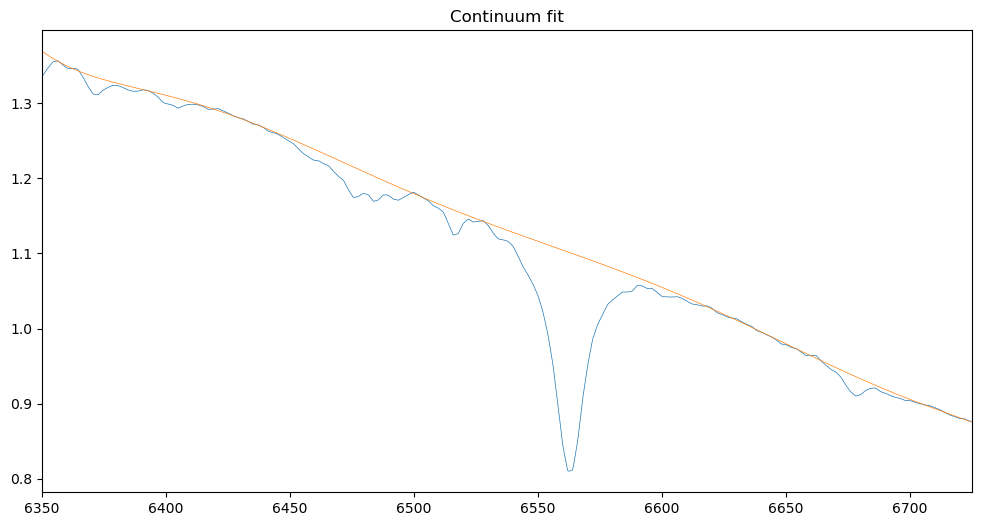

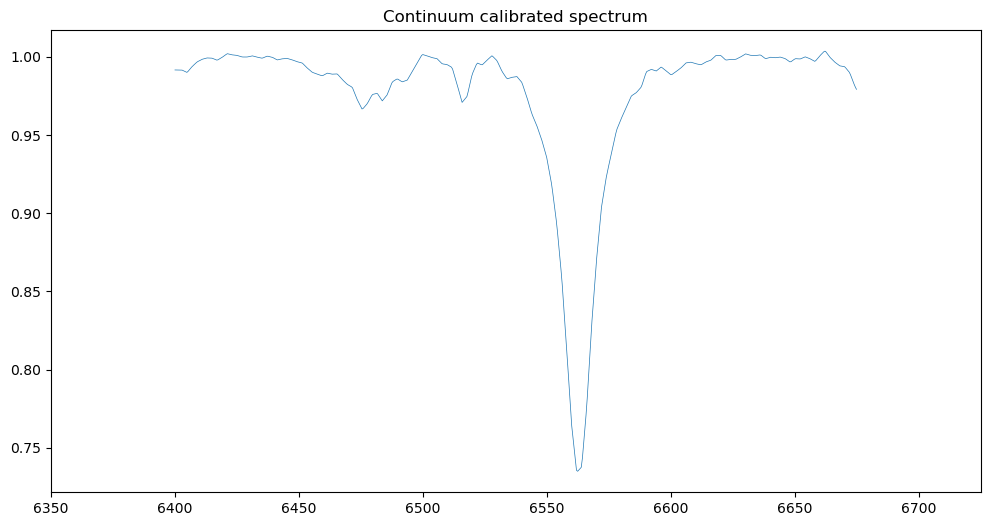

amp = -6.014240864184088 
mu = 6562.78353807593 
sigma = 0.6812506966010464 
gamma = 7.105968325519946 
offset = 1.0 
chi2 = 0.0001464650673818579


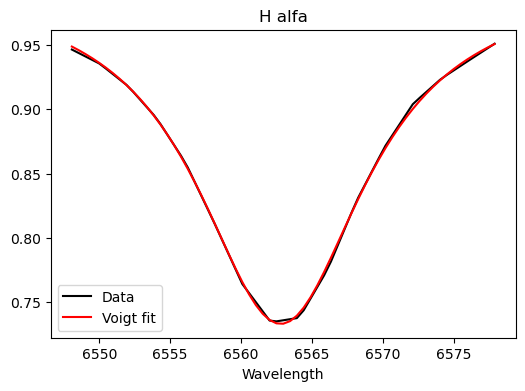

Lambda =  6562.78353807593 Eq Width = 6.014240864184088 FWHM =  14.403743739772052 Intensity =  -0.26699544157507515


#### H alfa optimization

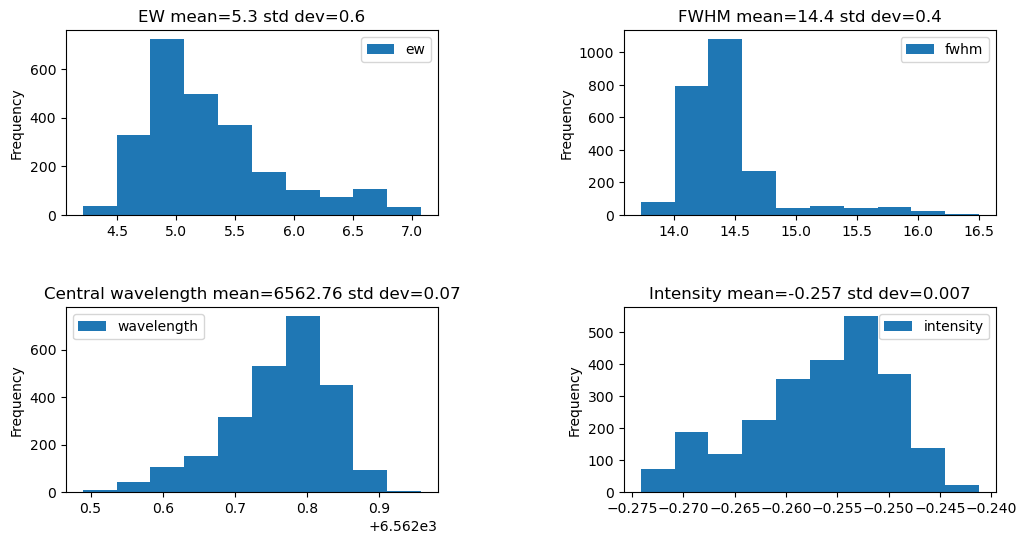

#### H alfa re-fit with best parameters

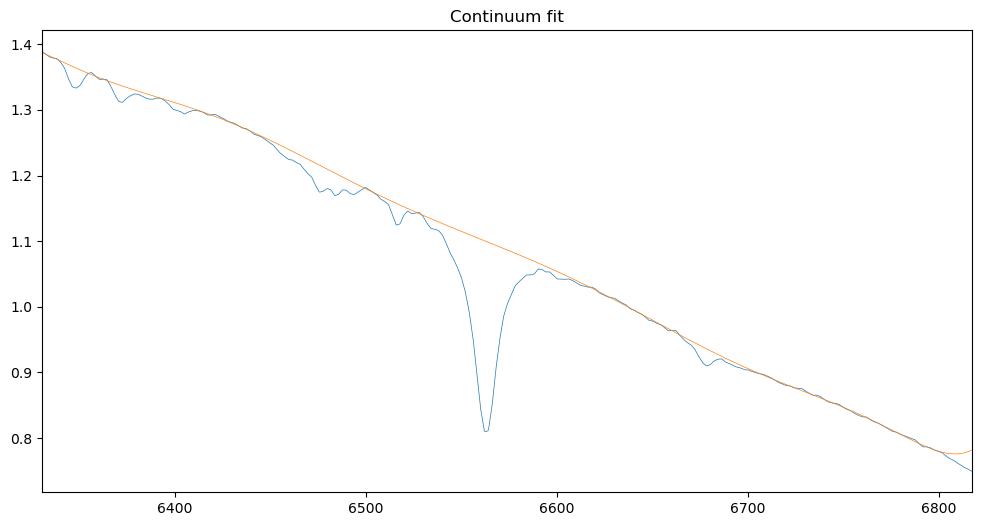

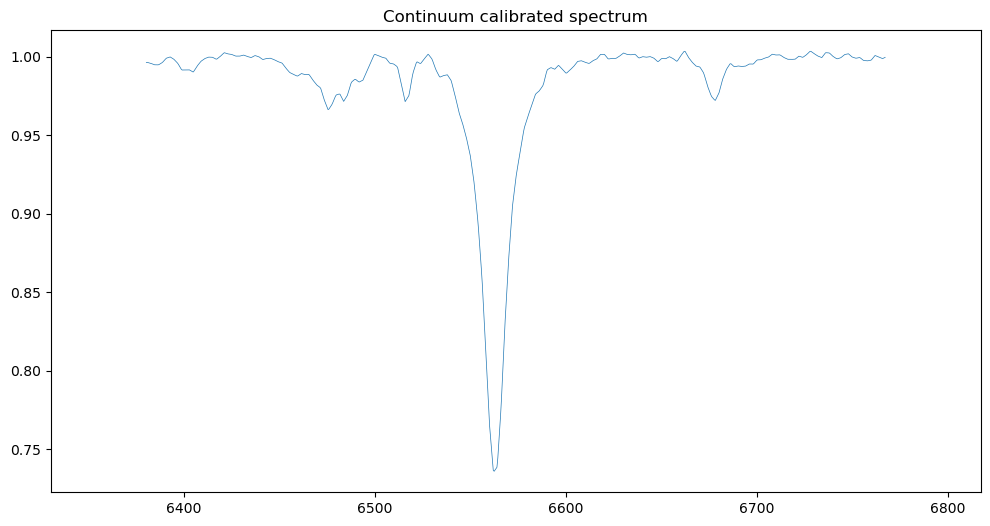

amp = -5.771817059940232 
mu = 6562.783588841037 
sigma = 2.0187581081924315 
gamma = 6.412916543458772 
offset = 1.0 
chi2 = 0.0012238660257325098


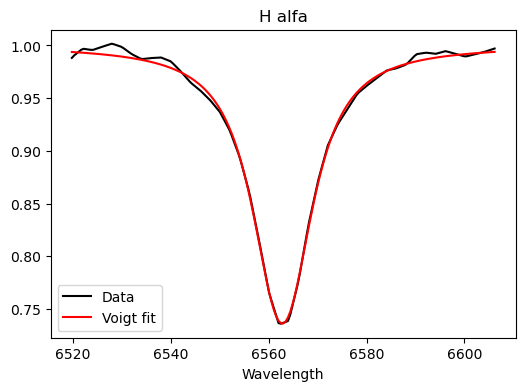

Lambda =  6562.783588841037 Eq Width = 5.771817059940232 FWHM =  14.487539670661743 Intensity =  -0.2639610757077068


### Measuring H beta

#### H beta preliminary fit

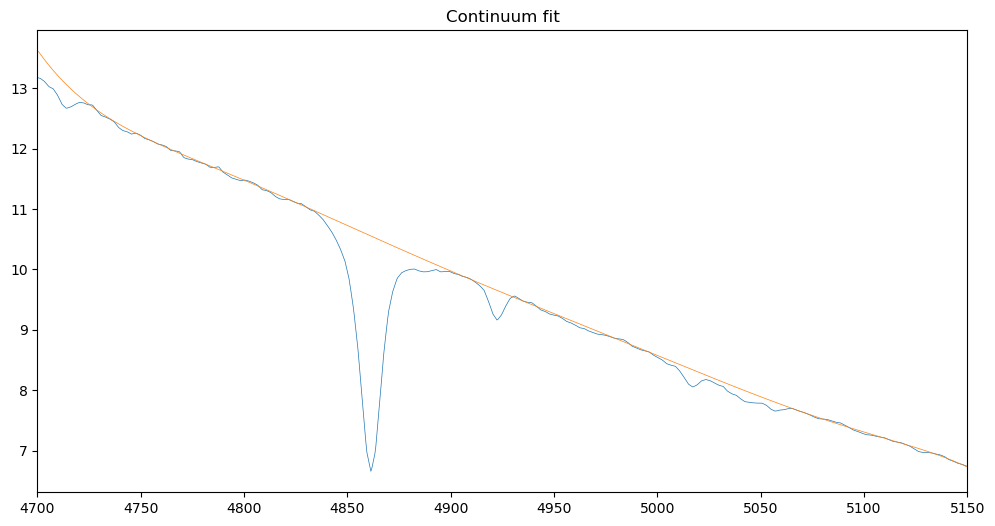

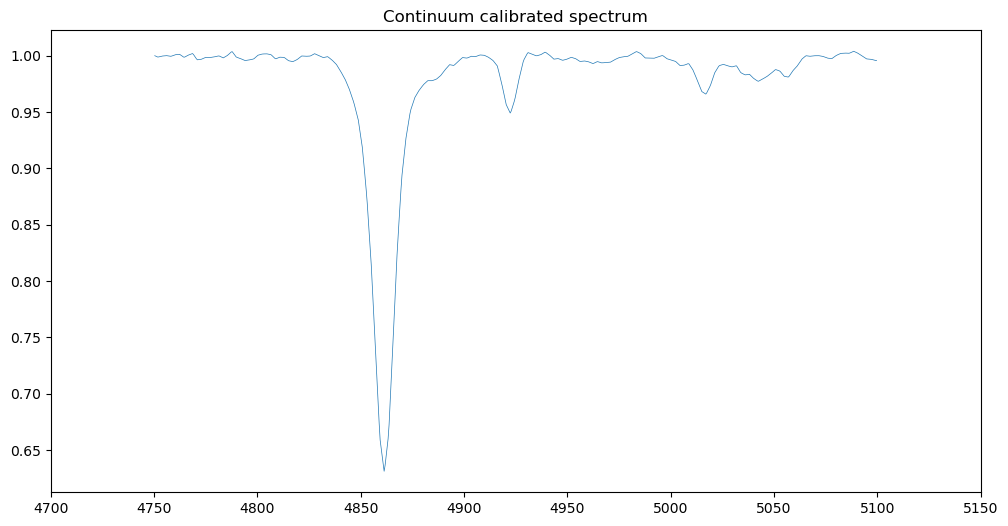

amp = -6.288517477206818 
mu = 4861.222012120437 
sigma = 3.091732789889937 
gamma = 4.042147659620374 
offset = 1.0 
chi2 = 0.000592393876461535


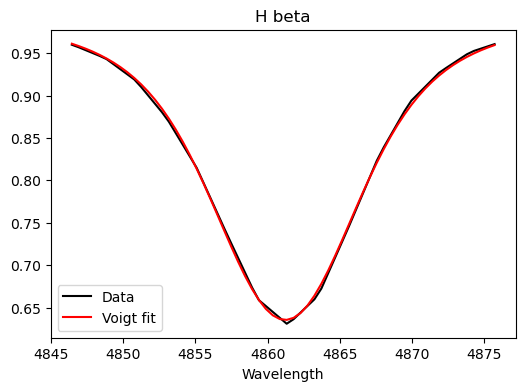

Lambda =  4861.222012120437 Eq Width = 6.288517477206818 FWHM =  12.517068953447446 Intensity =  -0.3644451204214918


#### H beta optimization

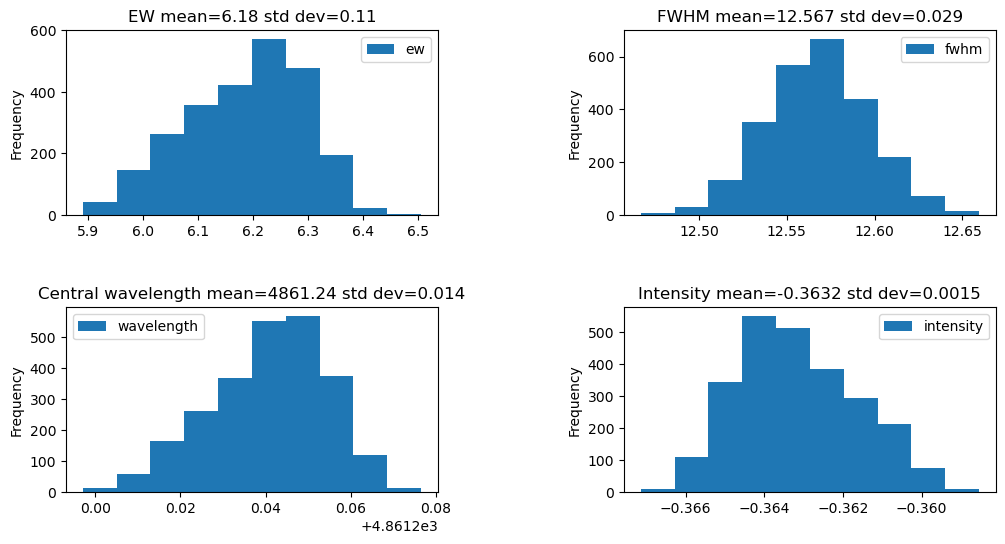

#### H beta re-fit with best parameters

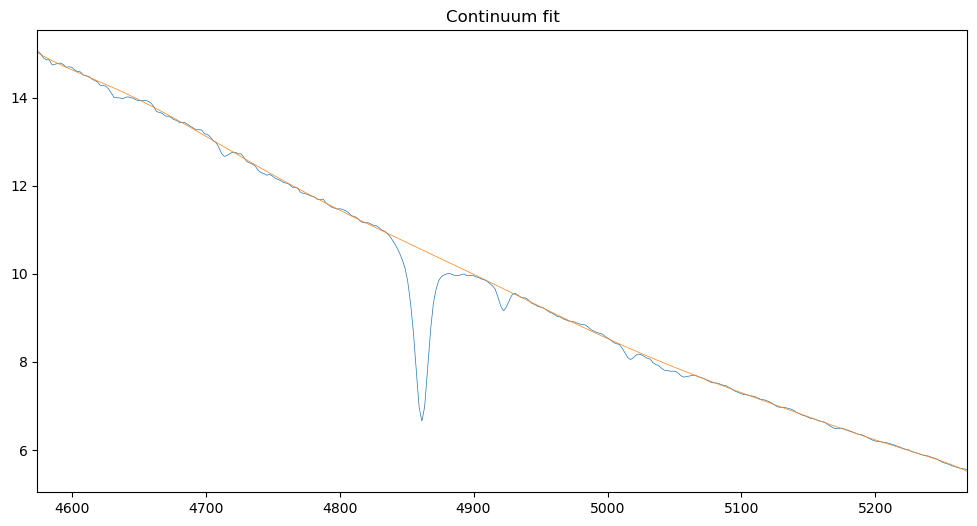

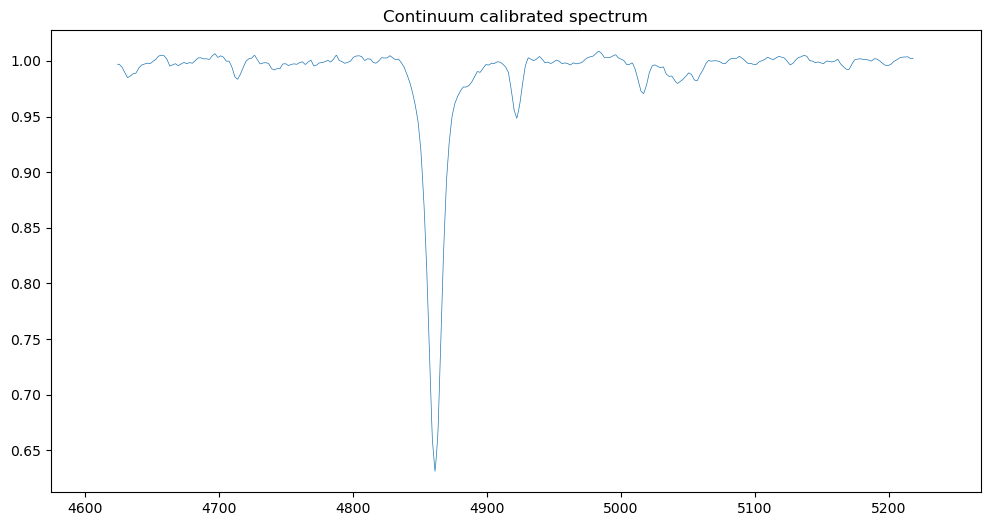

amp = -6.216484340580408 
mu = 4861.253716912919 
sigma = 3.2579837756218426 
gamma = 3.8417553045617048 
offset = 1.0 
chi2 = 0.002272220355883334


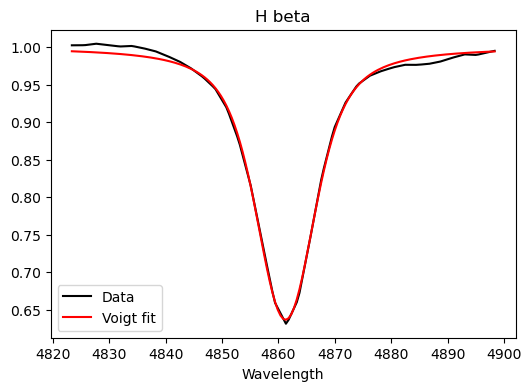

Lambda =  4861.253716912919 Eq Width = 6.216484340580408 FWHM =  12.572019983196153 Intensity =  -0.3635914742078065


### Measuring H gamma

#### H gamma preliminary fit

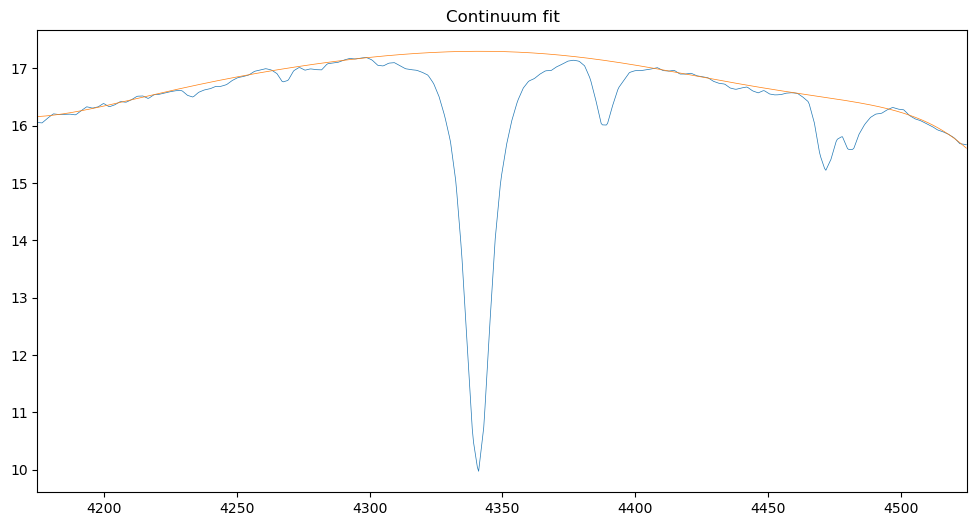

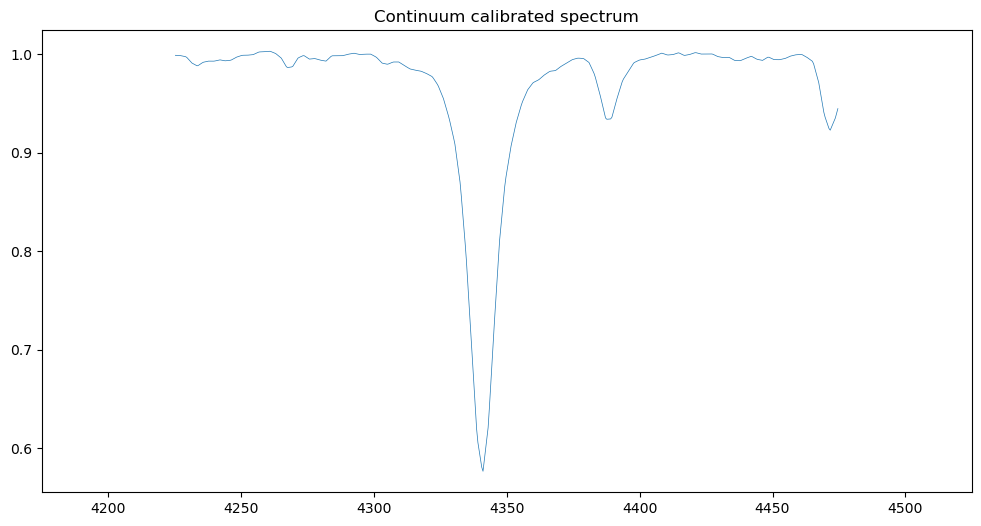

amp = -7.388929414376443 
mu = 4340.799076755625 
sigma = 2.1885966806015107 
gamma = 4.849048154004169 
offset = 1.0 
chi2 = 0.0006051517114699098


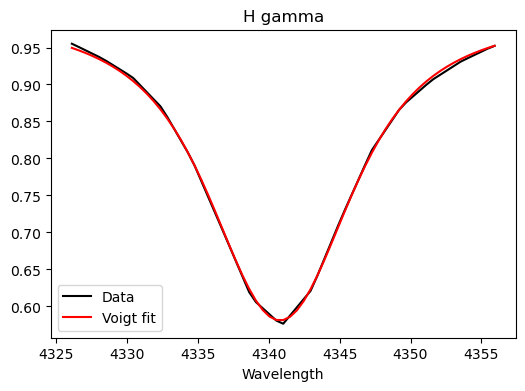

Lambda =  4340.799076755625 Eq Width = 7.388929414376443 FWHM =  12.03537218514522 Intensity =  -0.41888567215582934


#### H gamma optimization

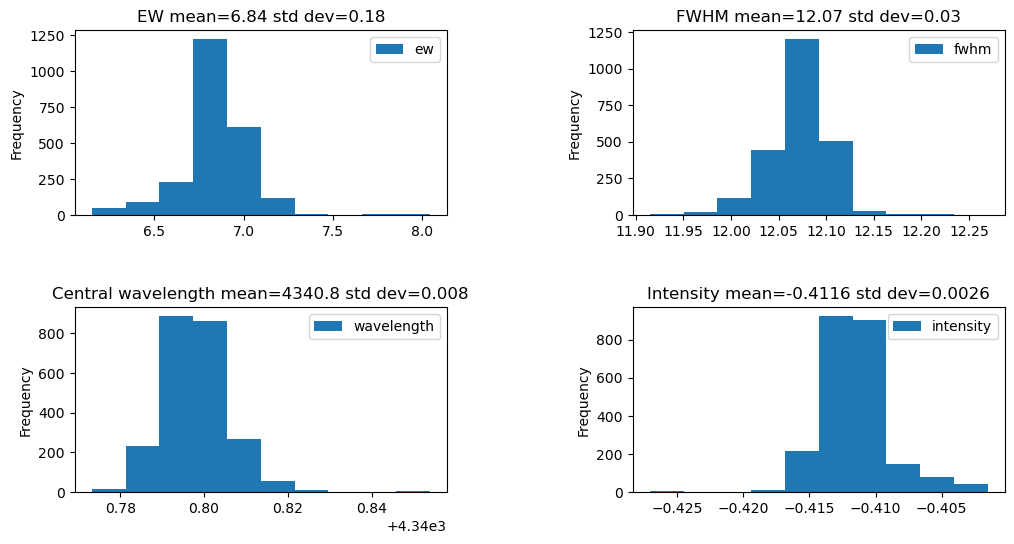

#### H gamma re-fit with best parameters

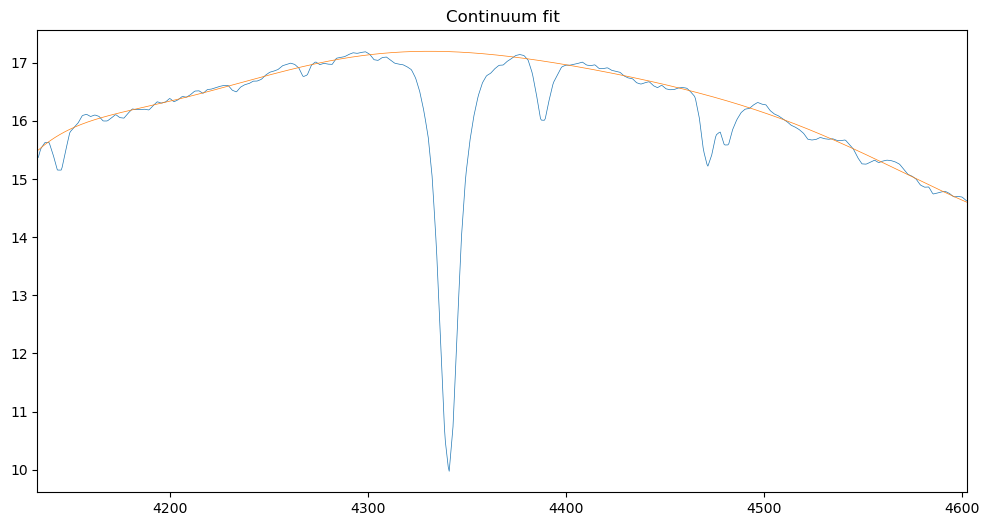

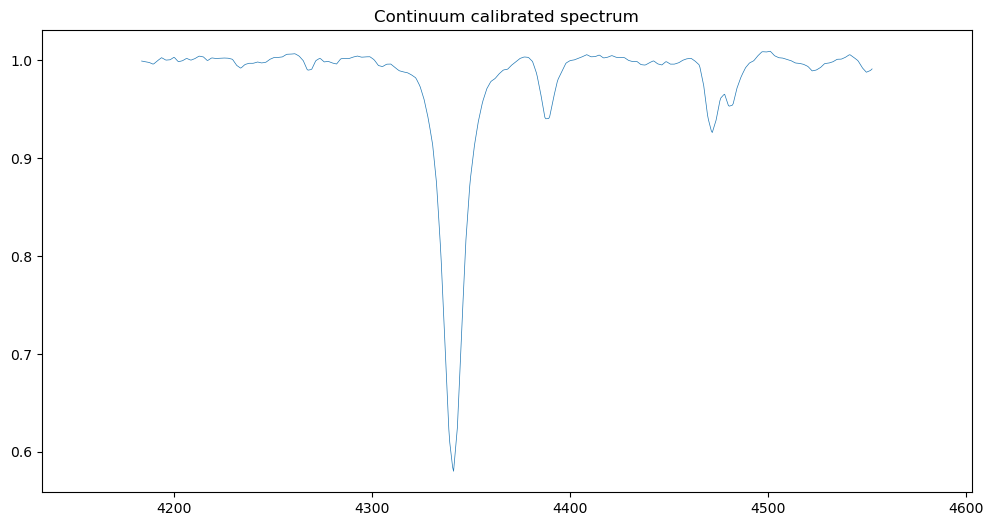

amp = -6.847171151717402 
mu = 4340.791666025552 
sigma = 2.9992049404988563 
gamma = 3.8785335576632156 
offset = 1.0 
chi2 = 0.001733856503810771


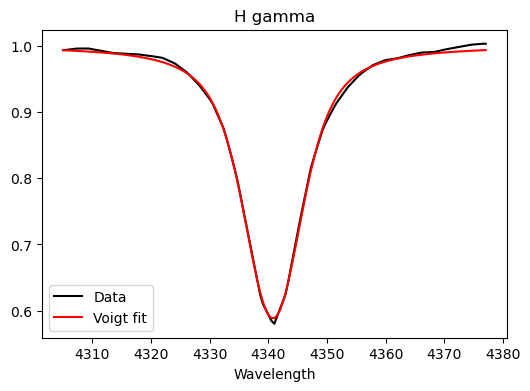

Lambda =  4340.791666025552 Eq Width = 6.847171151717402 FWHM =  12.078726285407942 Intensity =  -0.4118079625337855


### Measuring He I 4009

#### He I 4009 preliminary fit

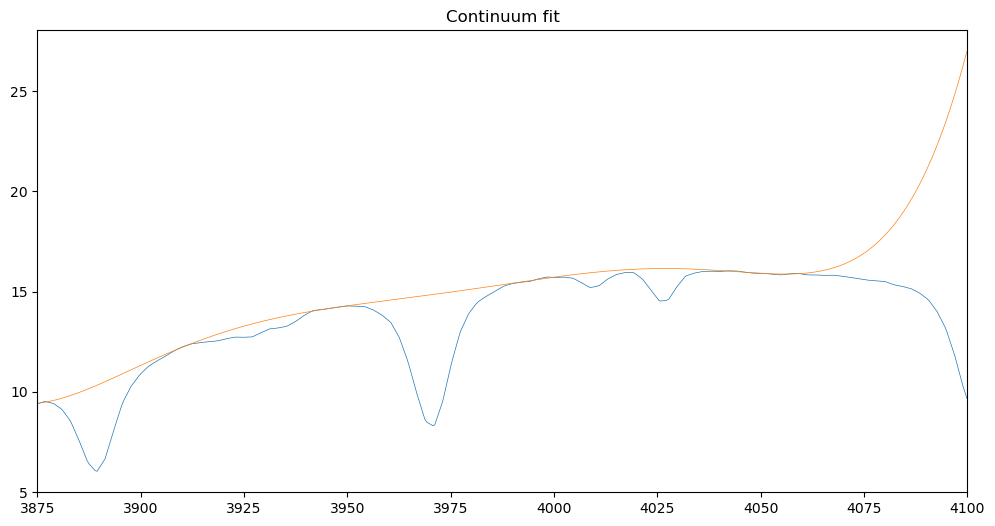

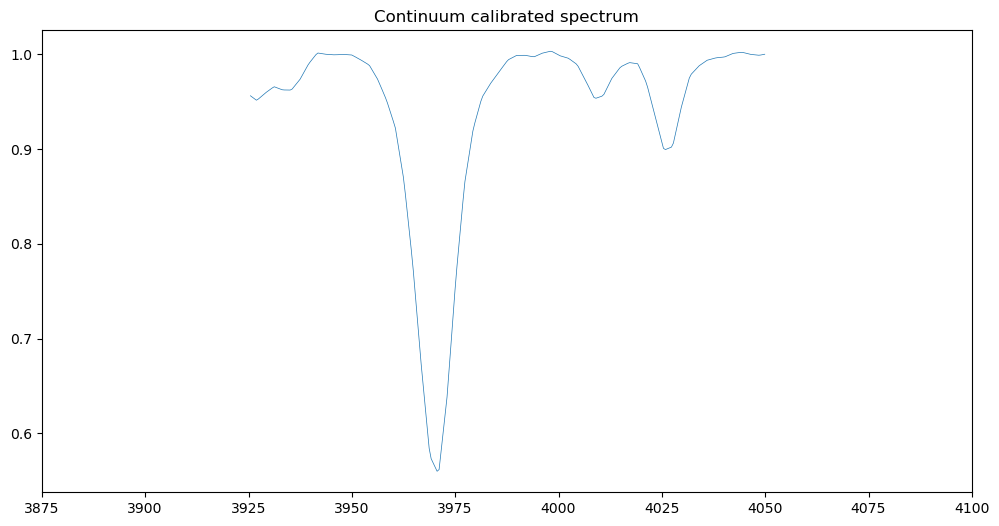

amp = -0.04184058750113088 
mu = 4009.94876704618 
sigma = 3.841157707390056 
offset = 1.0 
chi2 =  0.00047055060587642615


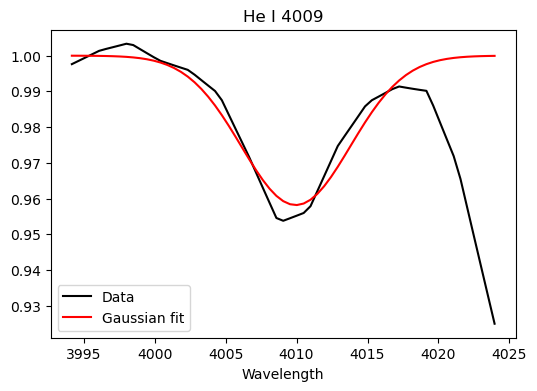

Lambda =  4009.94876704618 Eq Width = 0.4028560096462509 FWHM =  9.045926400903582 Intensity =  -0.04184058750113088


#### He I 4009 optimization

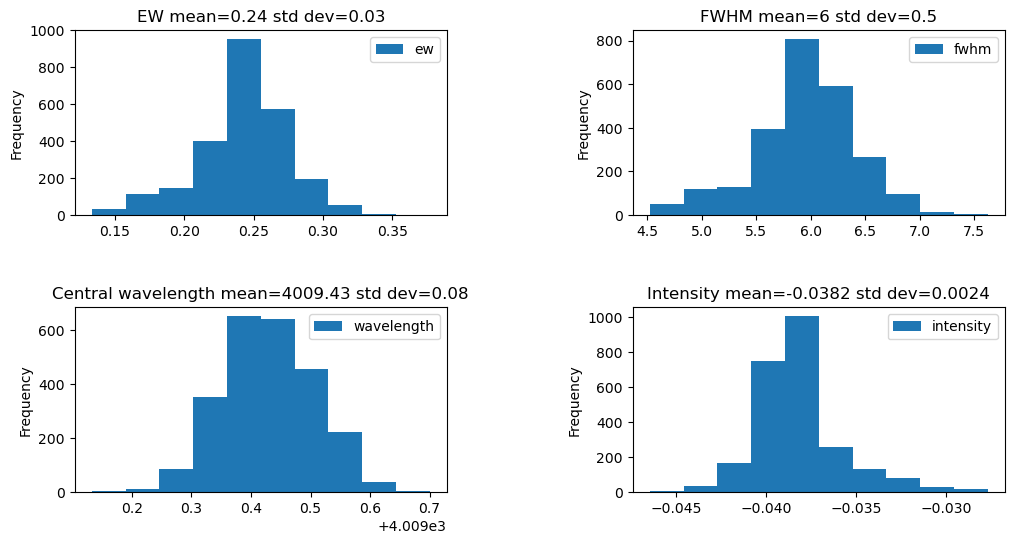

#### He I 4009 re-fit with best parameters

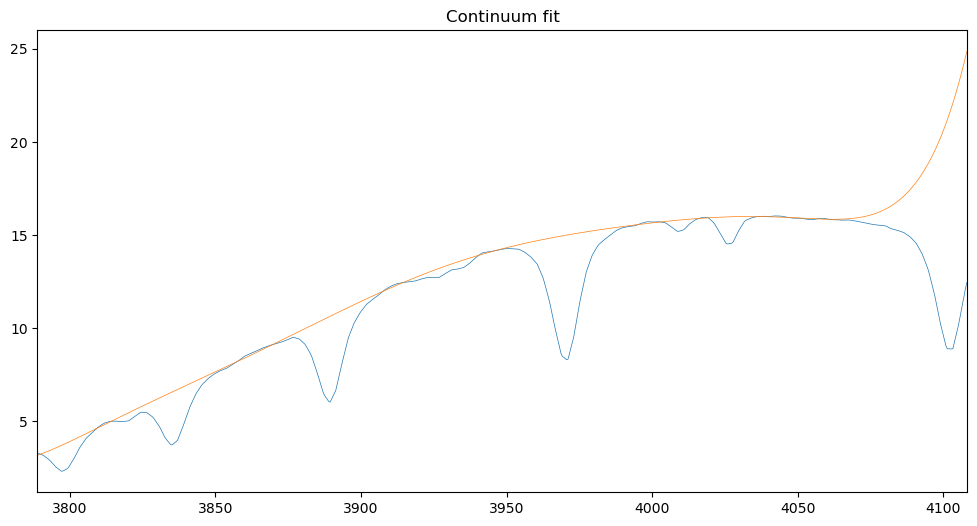

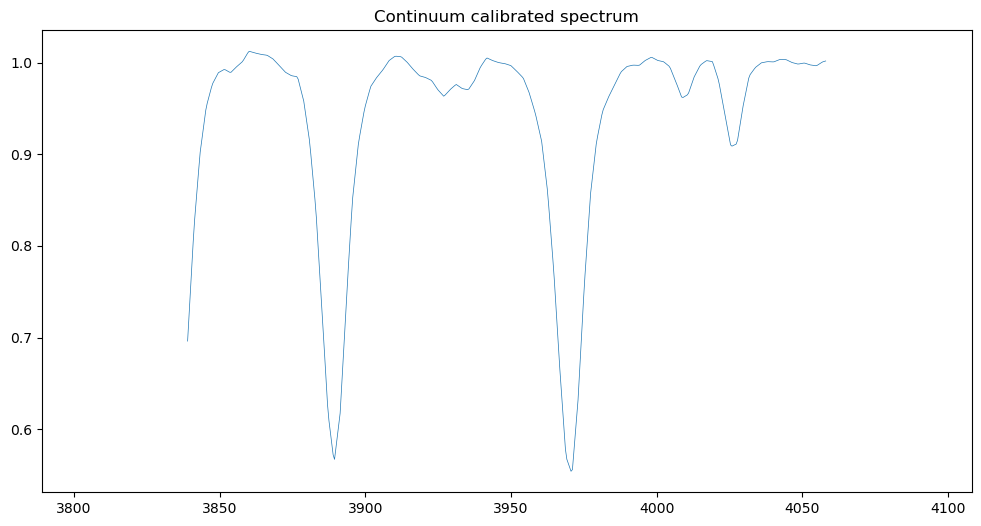

amp = -0.0385352765060496 
mu = 4009.480305174474 
sigma = 2.5382231878987804 
offset = 1.0 
chi2 =  1.3153531868410424e-05


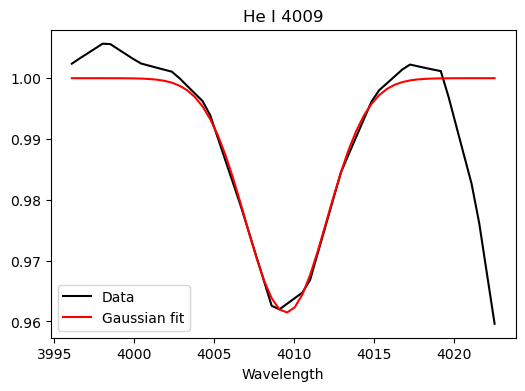

Lambda =  4009.480305174474 Eq Width = 0.24517614999674756 FWHM =  5.977515607501628 Intensity =  -0.0385352765060496


### Measuring He I 4026

#### He I 4026 preliminary fit

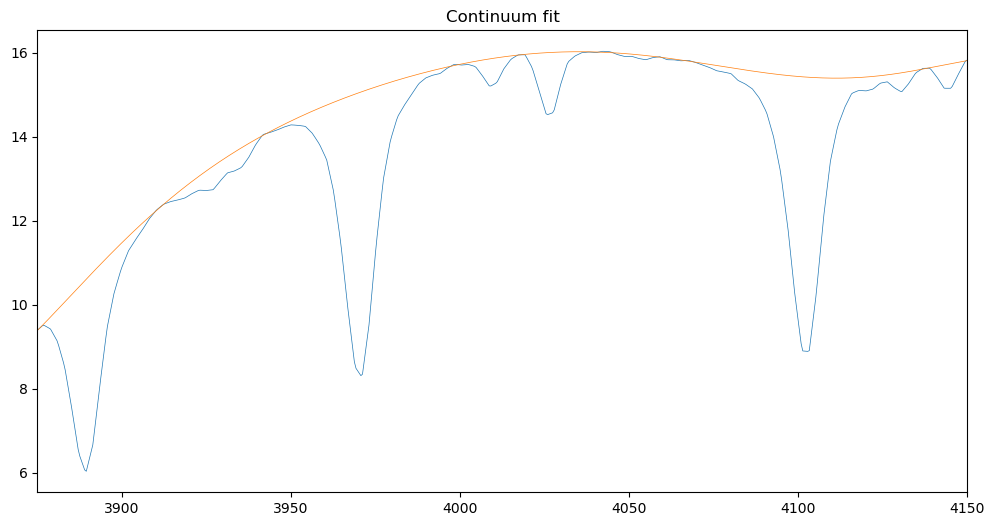

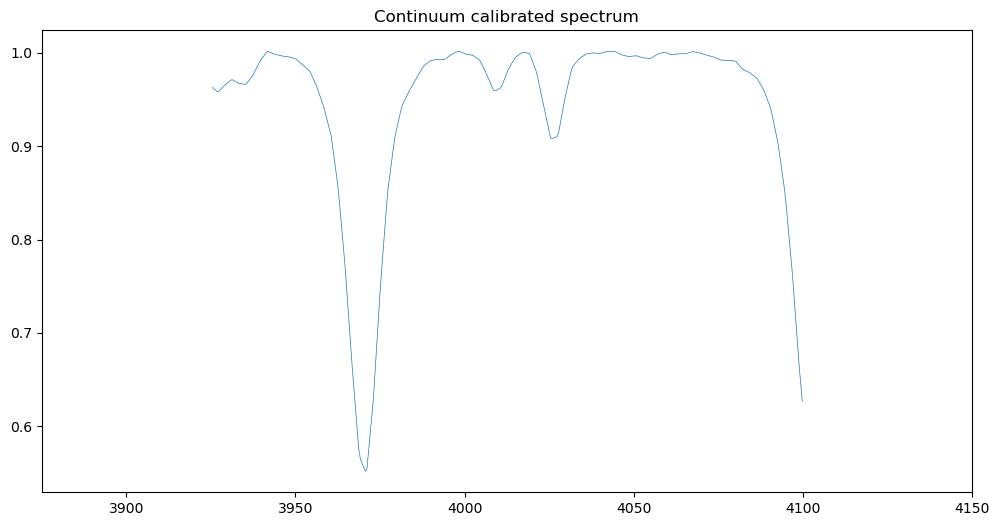

amp = -0.0933251705939423 
mu = 4026.3707457583473 
sigma = 2.977871793390014 
offset = 1.0 
chi2 =  5.1187247393873626e-05


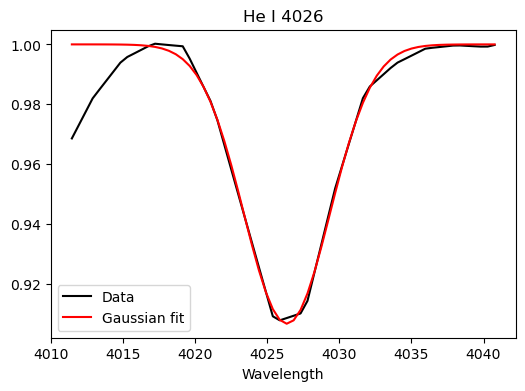

Lambda =  4026.3707457583473 Eq Width = 0.6966180492209717 FWHM =  7.012888073433483 Intensity =  -0.0933251705939423


#### He I 4026 optimization

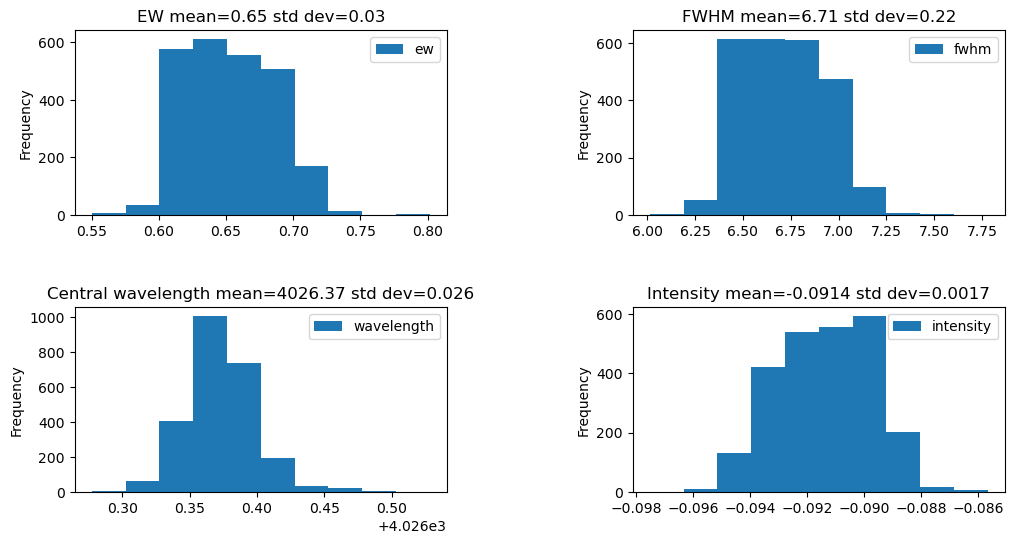

#### He I 4026 re-fit with best parameters

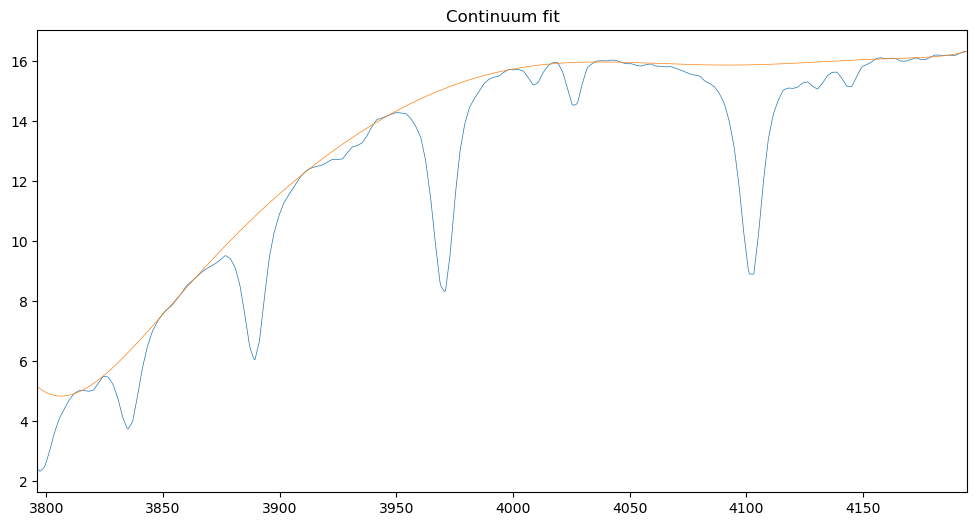

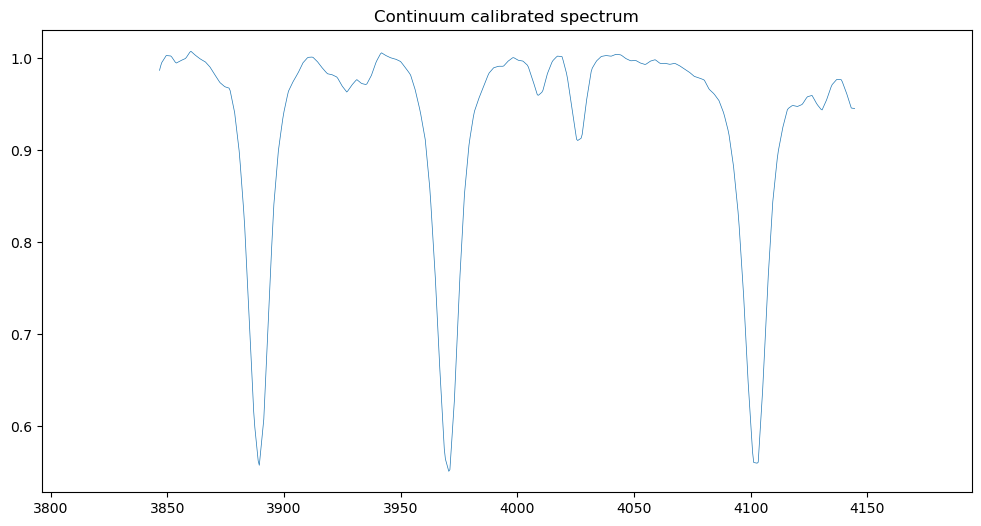

amp = -0.09135365699506708 
mu = 4026.3495274032575 
sigma = 2.8549697958588496 
offset = 1.0 
chi2 =  5.707592068075113e-05


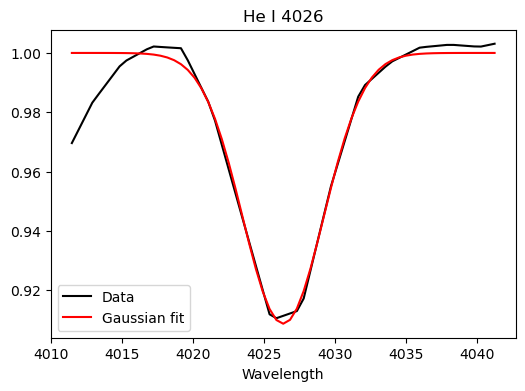

Lambda =  4026.3495274032575 Eq Width = 0.6537585617641879 FWHM =  6.7234538692475905 Intensity =  -0.09135365699506708


### Measuring He I 4388

#### He I 4388 preliminary fit

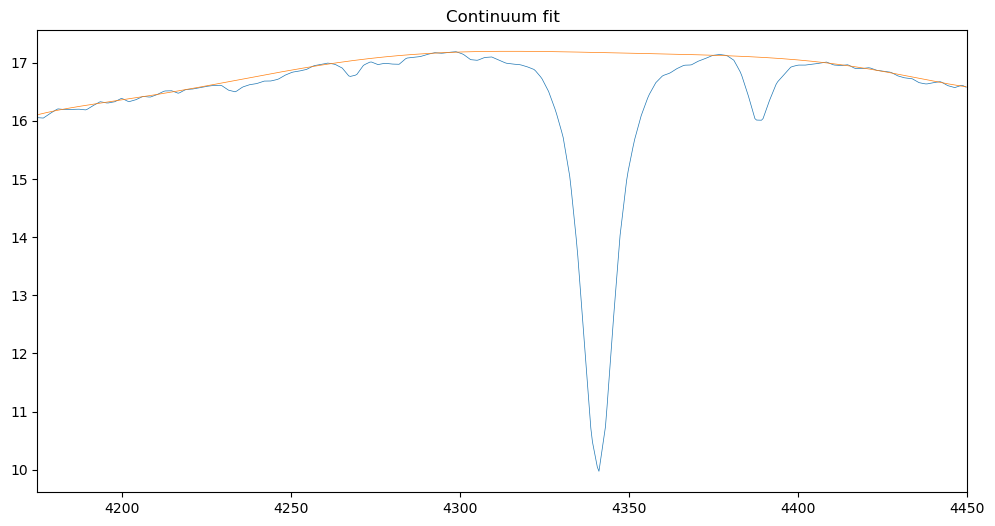

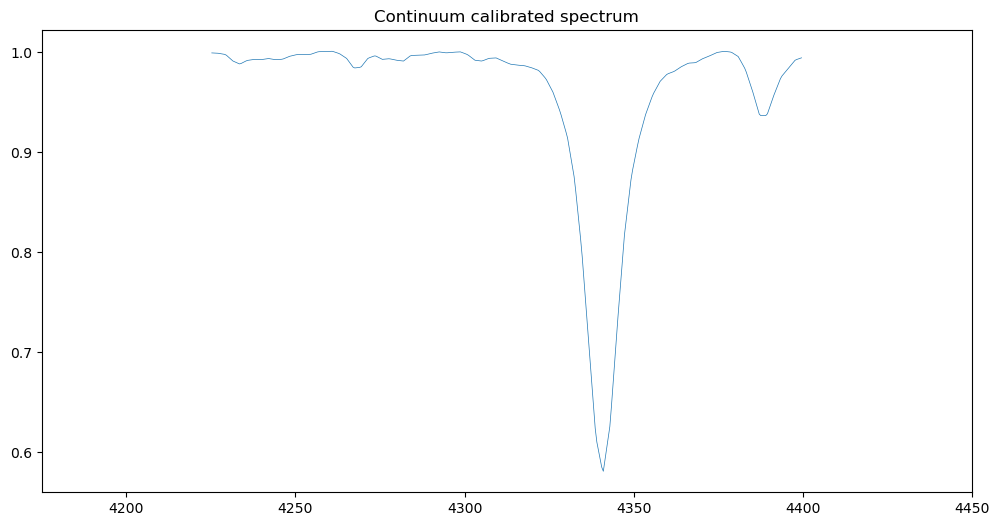

amp = -0.06211837231461713 
mu = 4388.717260583429 
sigma = 3.743626870327417 
offset = 1.0 
chi2 =  0.00035764787134962505


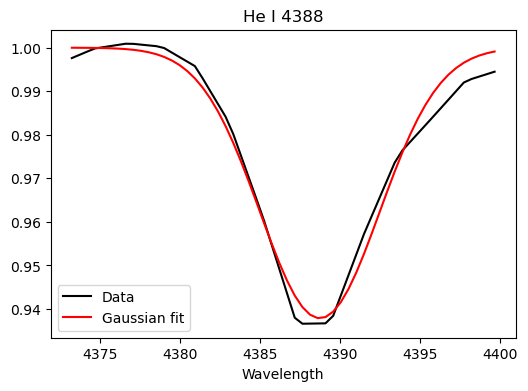

Lambda =  4388.717260583429 Eq Width = 0.582911411405188 FWHM =  8.816241279621067 Intensity =  -0.06211837231461713


#### He I 4388 optimization

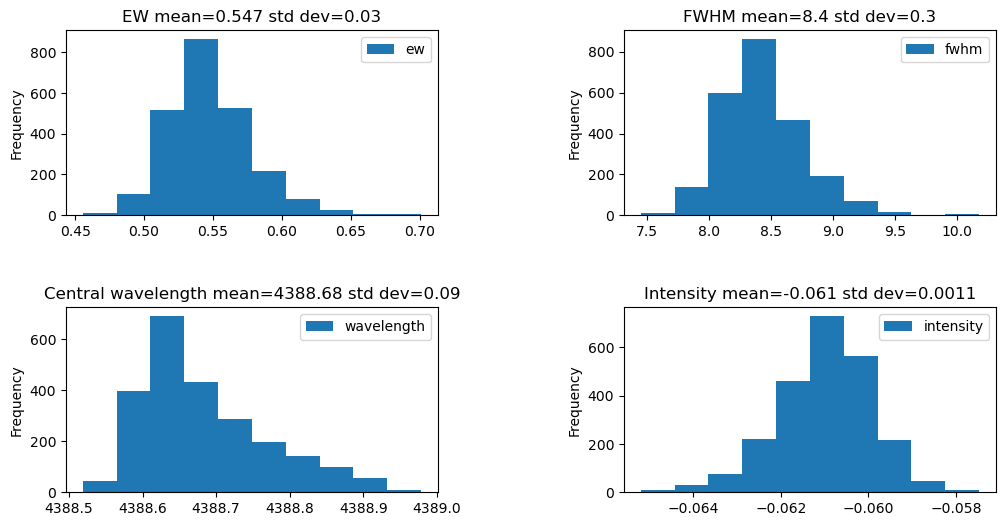

#### He I 4388 re-fit with best parameters

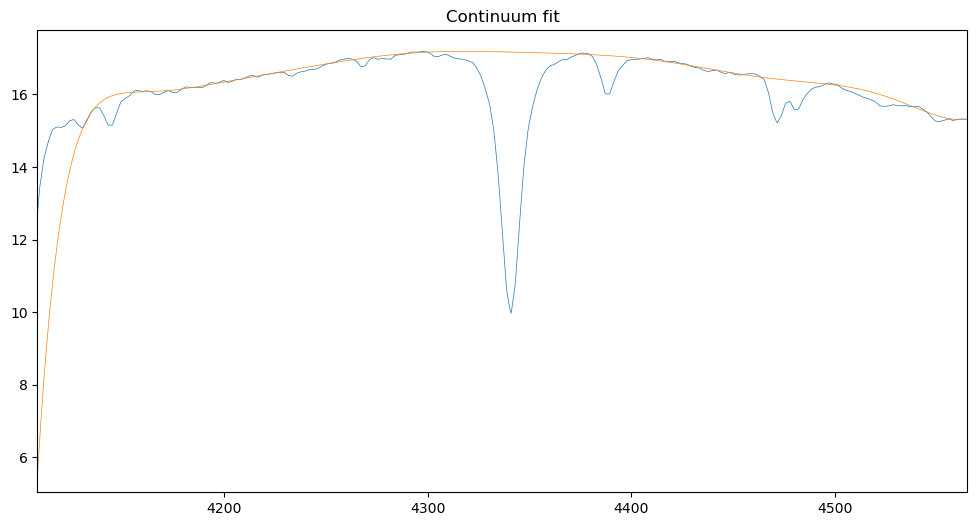

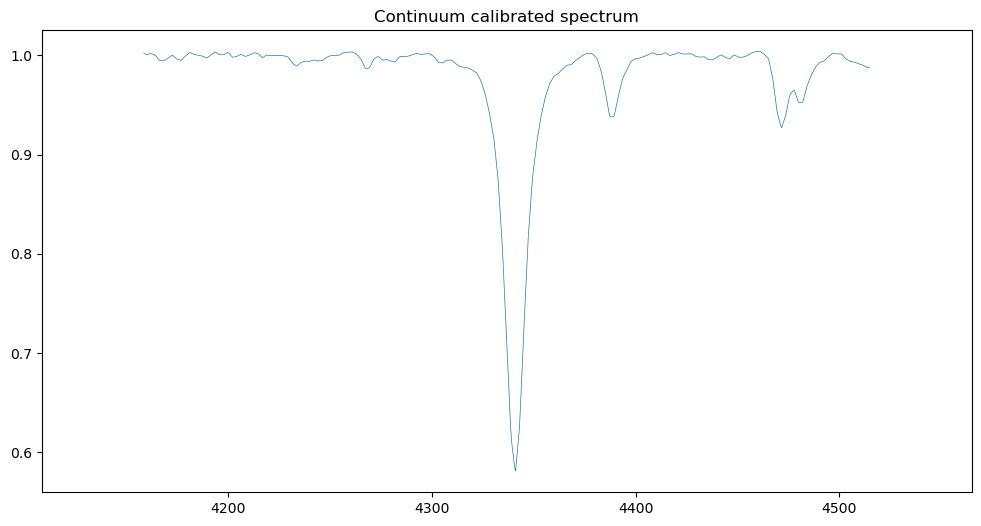

amp = -0.0612603878972777 
mu = 4388.685729714316 
sigma = 3.6209488905352094 
offset = 1.0 
chi2 =  0.0002866127145490782


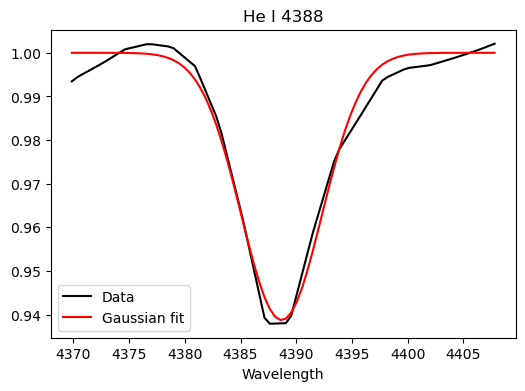

Lambda =  4388.685729714316 Eq Width = 0.5560221227170977 FWHM =  8.527334637210418 Intensity =  -0.0612603878972777


### Measuring He I 4922

#### He I 4922 preliminary fit

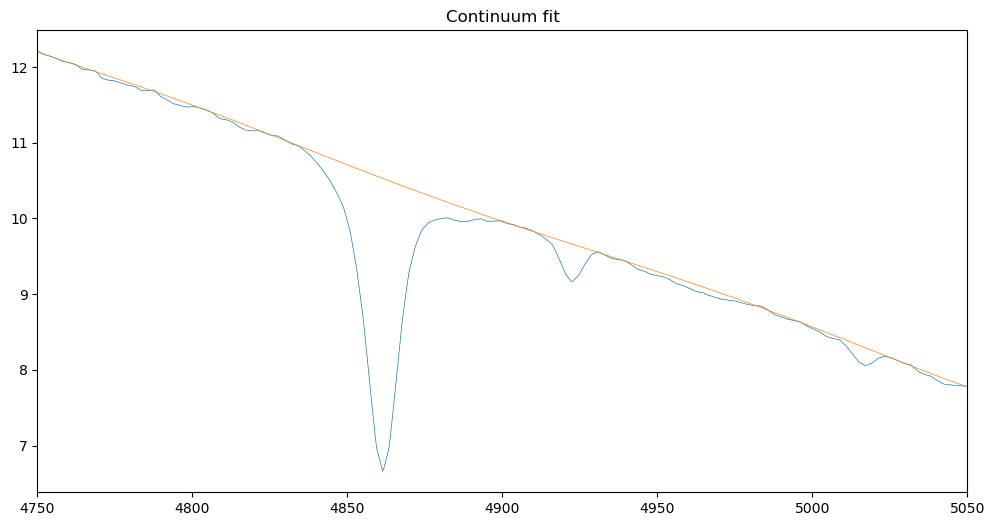

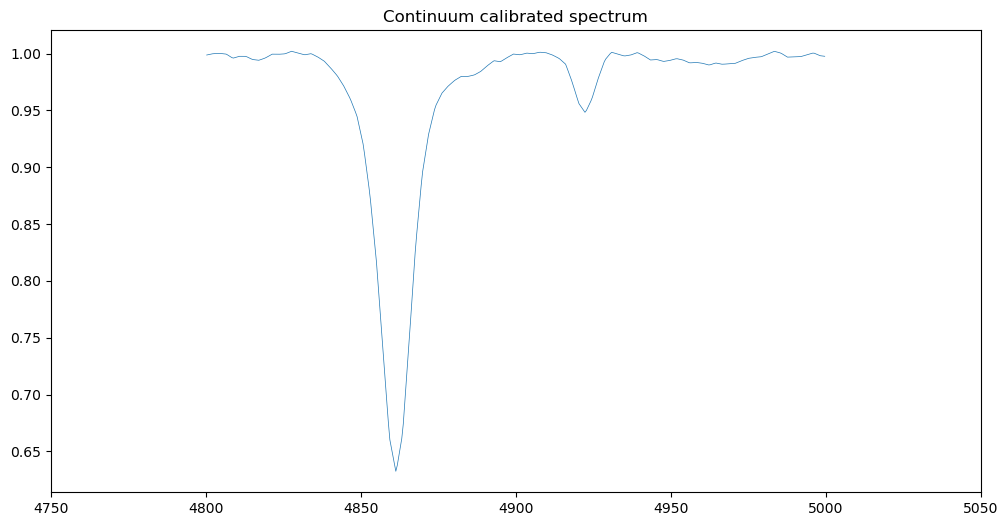

amp = -0.05027323089098792 
mu = 4922.1730294542285 
sigma = 3.3817498060743216 
offset = 1.0 
chi2 =  2.399364462533484e-05


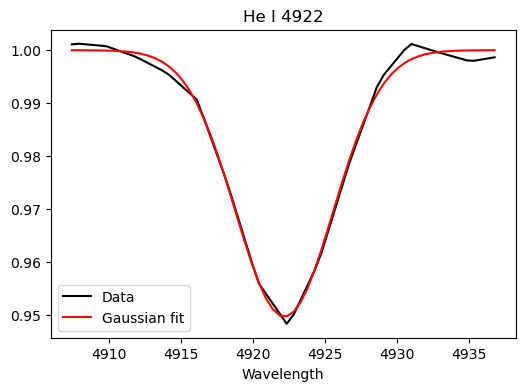

Lambda =  4922.1730294542285 Eq Width = 0.4261556048791198 FWHM =  7.9640207933050275 Intensity =  -0.05027323089098792


#### He I 4922 optimization

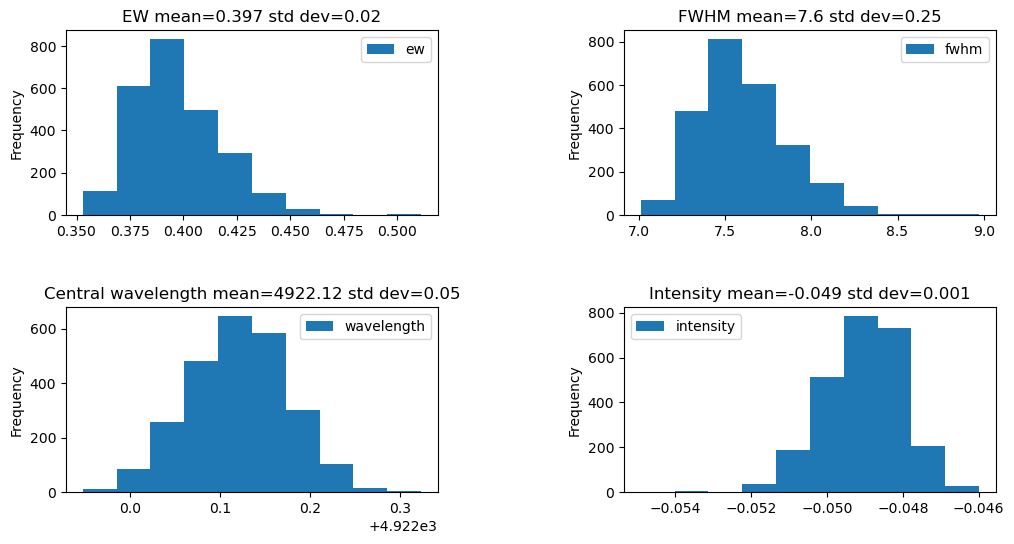

#### He I 4922 re-fit with best parameters

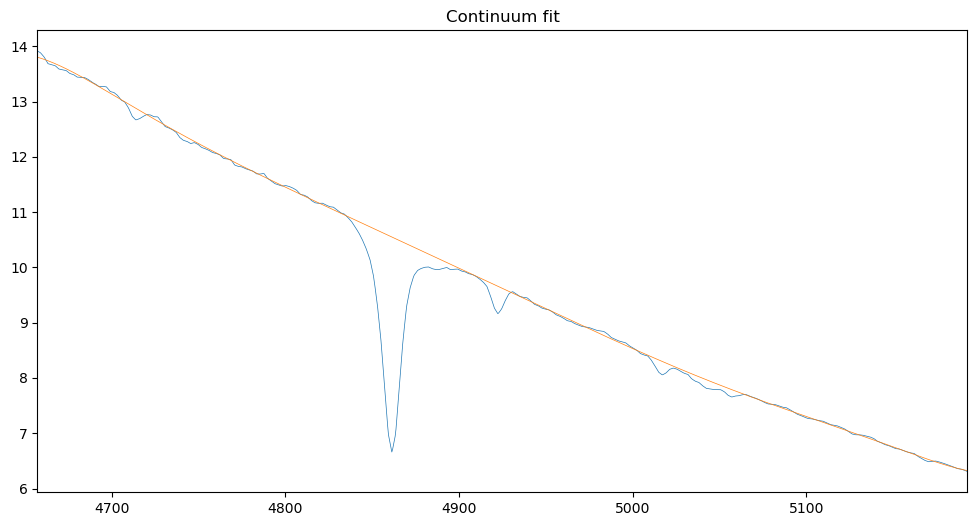

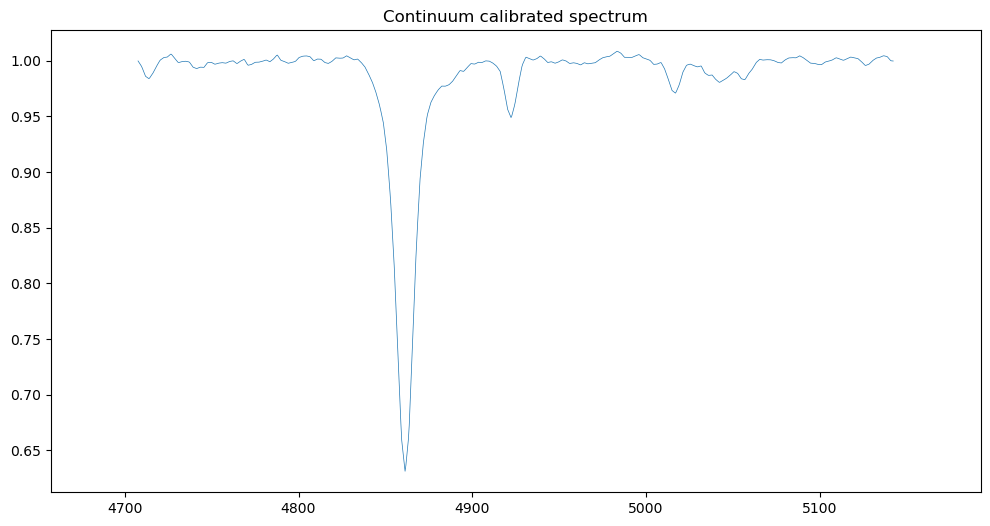

amp = -0.04993261301568232 
mu = 4922.079753818314 
sigma = 3.3395822232990025 
offset = 1.0 
chi2 =  4.1722929655689295e-05


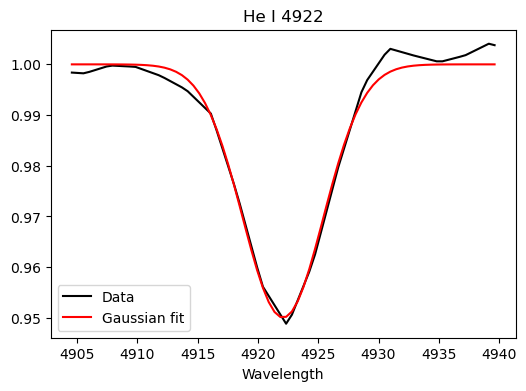

Lambda =  4922.079753818314 Eq Width = 0.41799045872562324 FWHM =  7.864716135869151 Intensity =  -0.04993261301568232


### Measuring He I 6678

#### He I 6678 preliminary fit

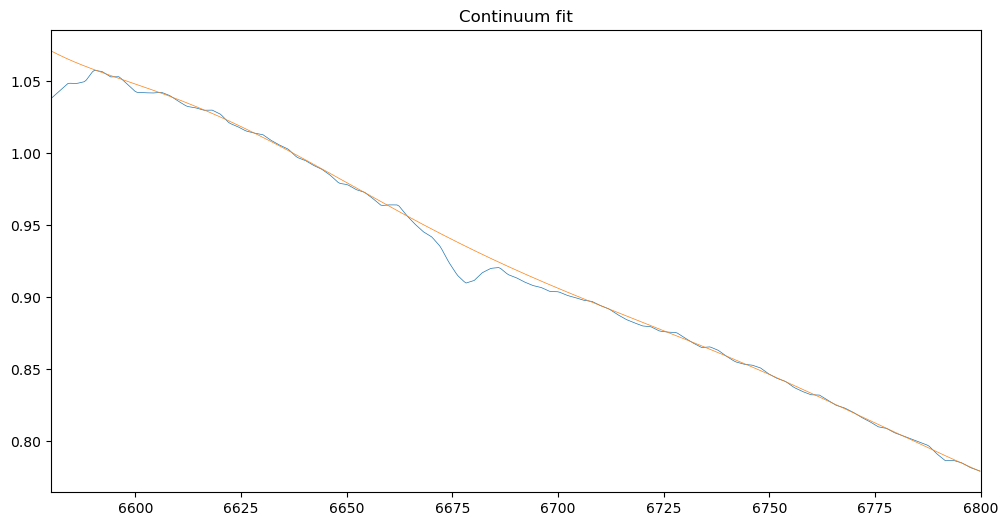

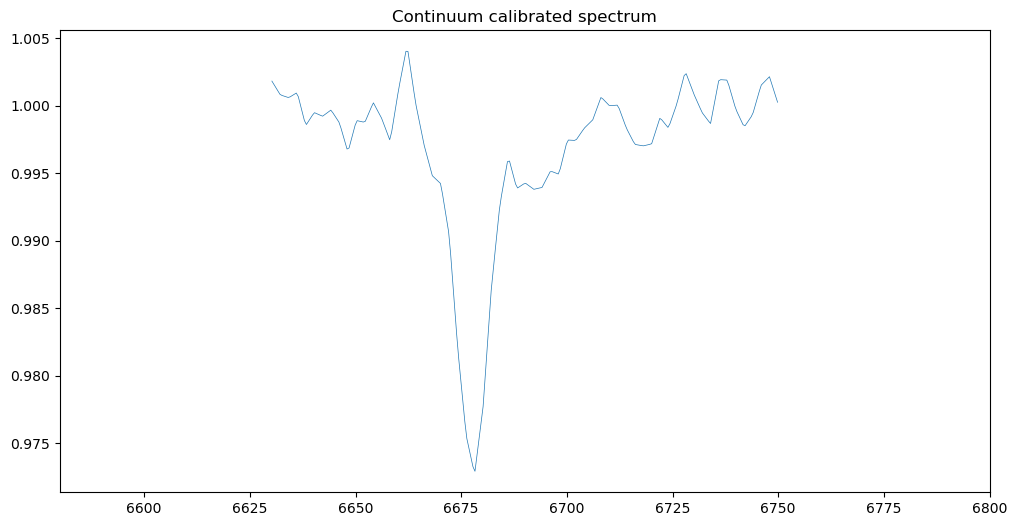

amp = -0.024951140292480786 
mu = 6677.738775167994 
sigma = 4.581850537151734 
offset = 1.0 
chi2 =  0.00012823274305991133


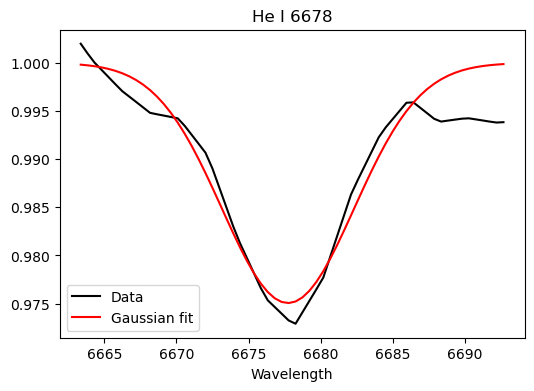

Lambda =  6677.738775167994 Eq Width = 0.28656374911331856 FWHM =  10.790258014992334 Intensity =  -0.024951140292480786


#### He I 6678 optimization

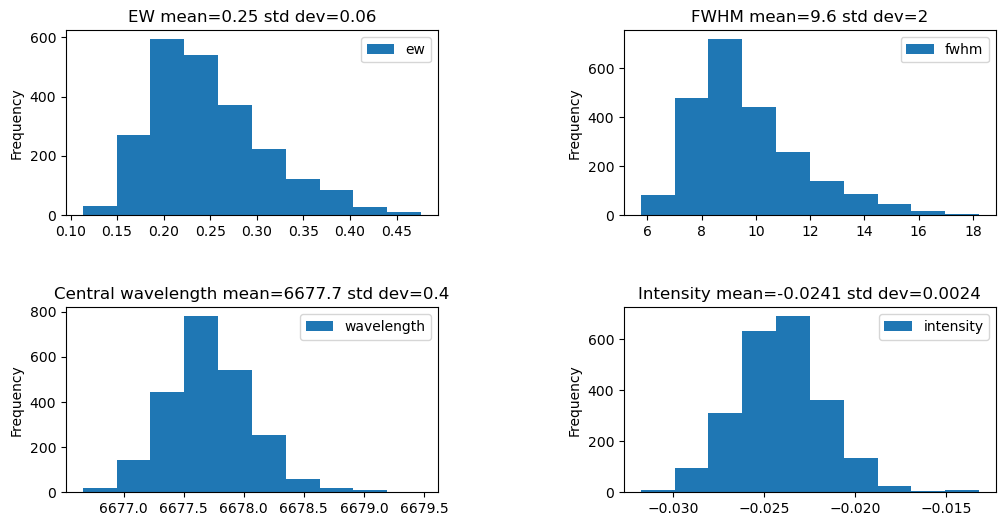

#### He I 6678 re-fit with best parameters

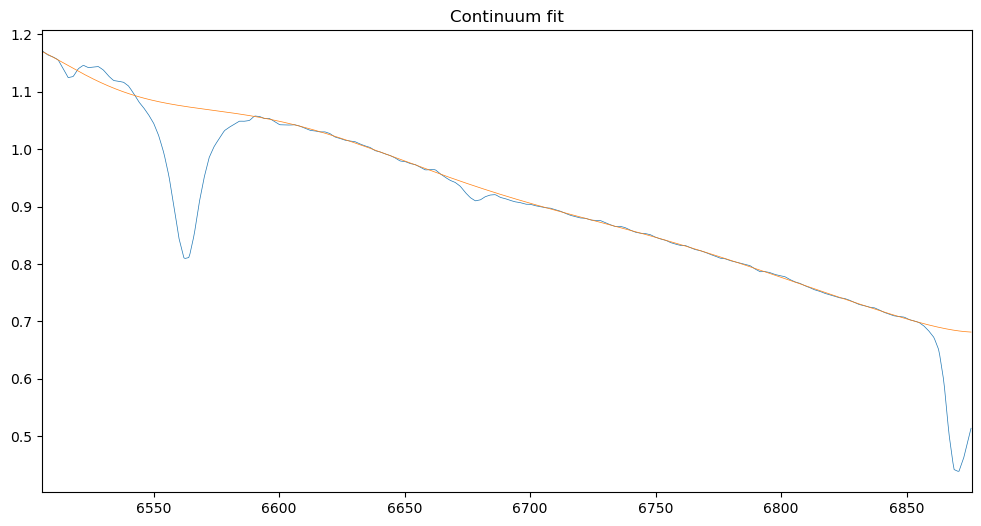

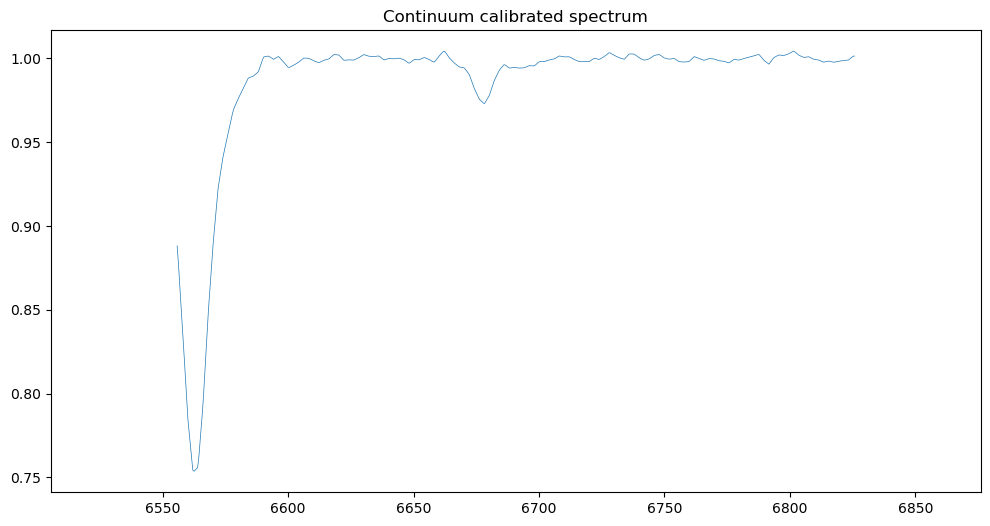

amp = -0.024964207564015226 
mu = 6677.723126828159 
sigma = 4.500888318102263 
offset = 1.0 
chi2 =  9.943435912332137e-05


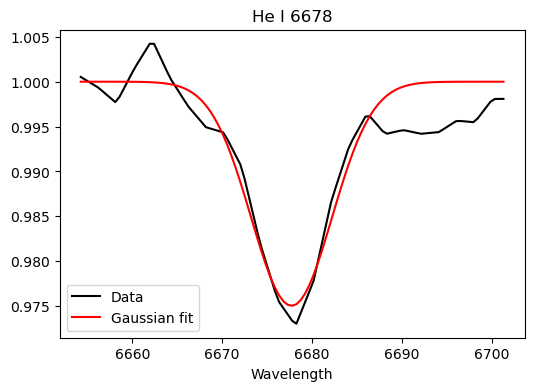

Lambda =  6677.723126828159 Eq Width = 0.281647535785111 FWHM =  10.59959198913083 Intensity =  -0.024964207564015226


In [31]:
summary_results = pd.DataFrame(columns=("line_name","wavelength","delta_wavelength","ew","delta_ew","fwhm","delta_fwhm","intensity","delta_intensity"))

i = 0

for measuring_line in measuring_lines:
    results = measure_line(wl, flux, measuring_line, show_param_dependencies=SHOW_PARAM_DEPENDENCIES)
    summary_results.loc[i] = results
    i = i + 1

## Measure All Blends

### Measuring He I/Mg II 4471-81

Blended lines= [{'name': 'He I 4471', 'wavelength': 4471.0}, {'name': 'Mg II 4481', 'wavelength': 4481.0}, {'name': 'Unknown 4490', 'wavelength': 4490.0}]


#### He I/Mg II 4471-81 preliminary fit

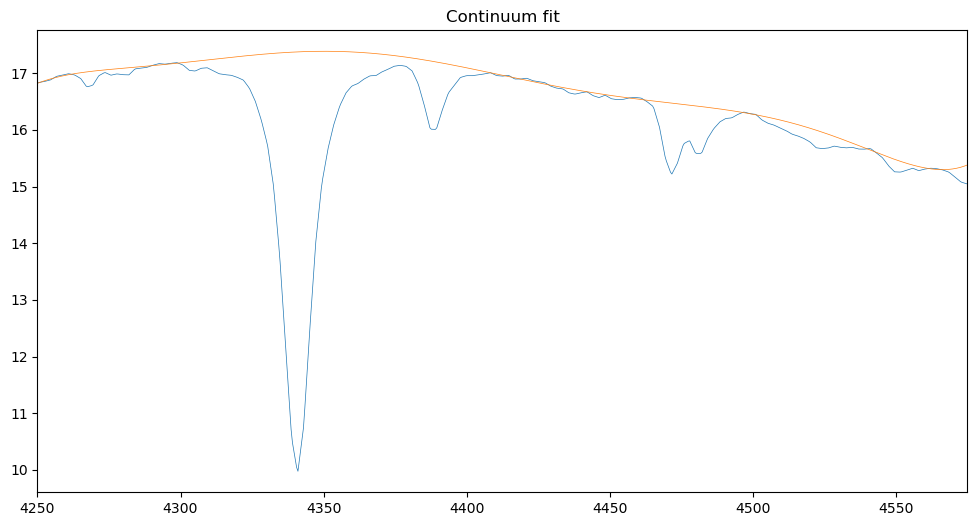

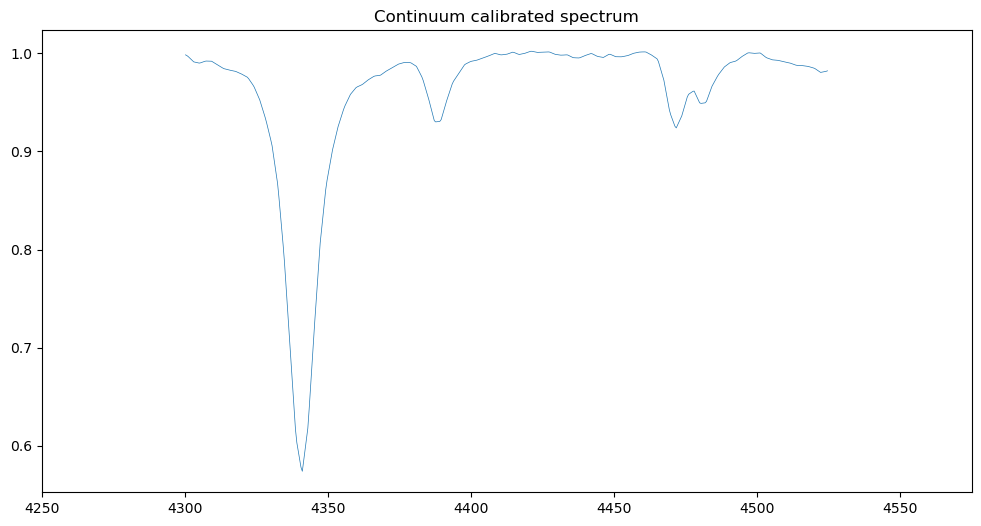

Fit window = (4444.5, 4516.5)
He I 4471 (gauss)
amp = -0.07409431476588255 
mu = 4471.612606747262 
sigma = 3.0599200504737984 
offset = 1.0 
chi2 = 0.002771390040612335


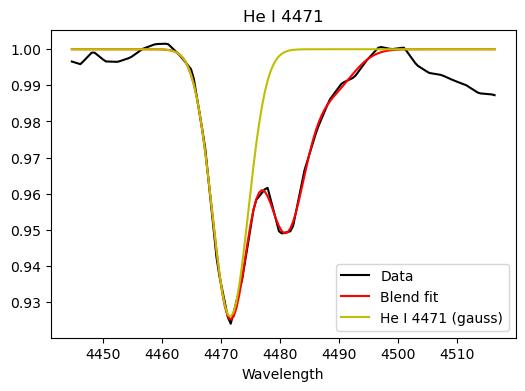

Mg II 4481 (gauss)
amp = -0.04884054727344408 
mu = 4480.931682397925 
sigma = 3.218924206753552 
offset = 1.0 
chi2 = 0.002771390040612335


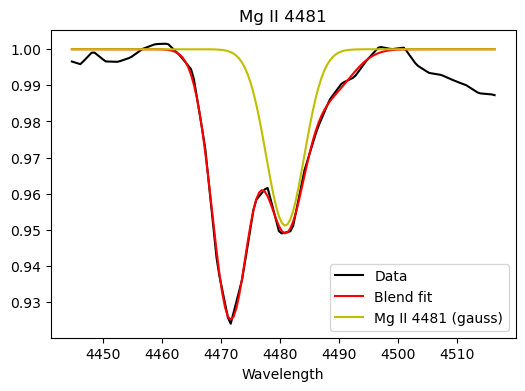

Unknown 4490 (gauss)
amp = -0.011329625341193026 
mu = 4488.577399004296 
sigma = 3.7501931567180424 
offset = 1.0 
chi2 = 0.002771390040612335


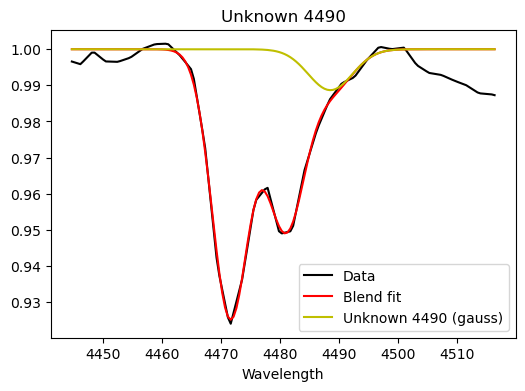

#### He I/Mg II 4471-81 optimization

#### Plotting results for He I 4471

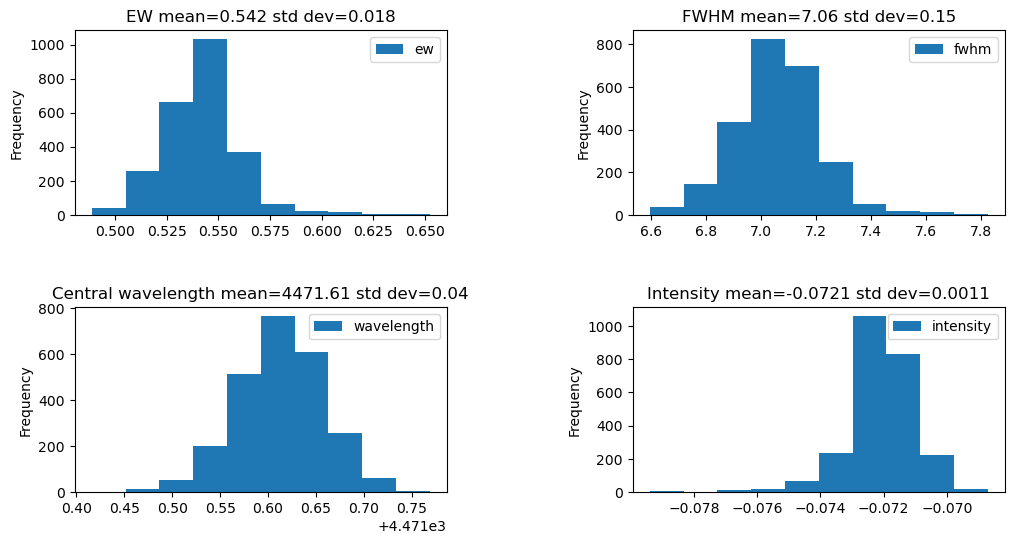

#### Plotting results for Mg II 4481

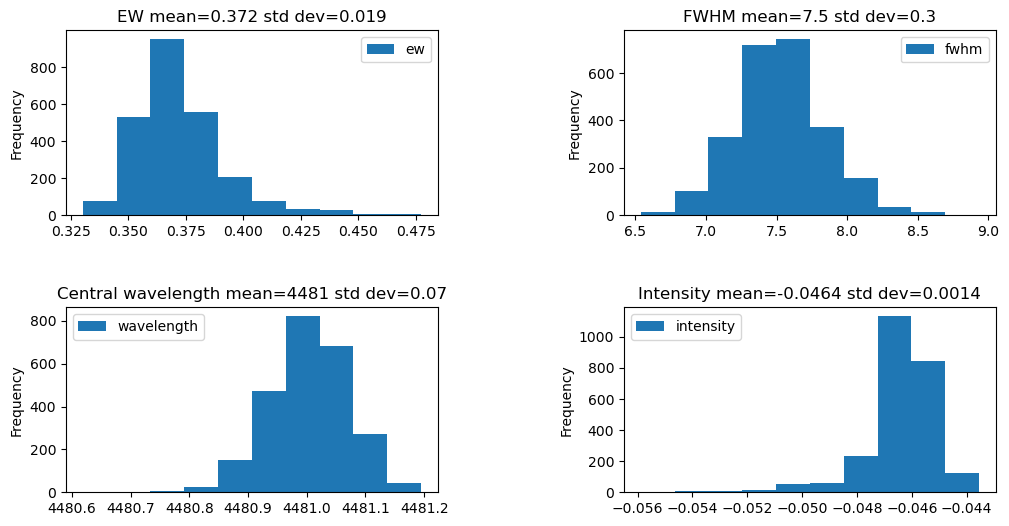

#### Plotting results for Unknown 4490

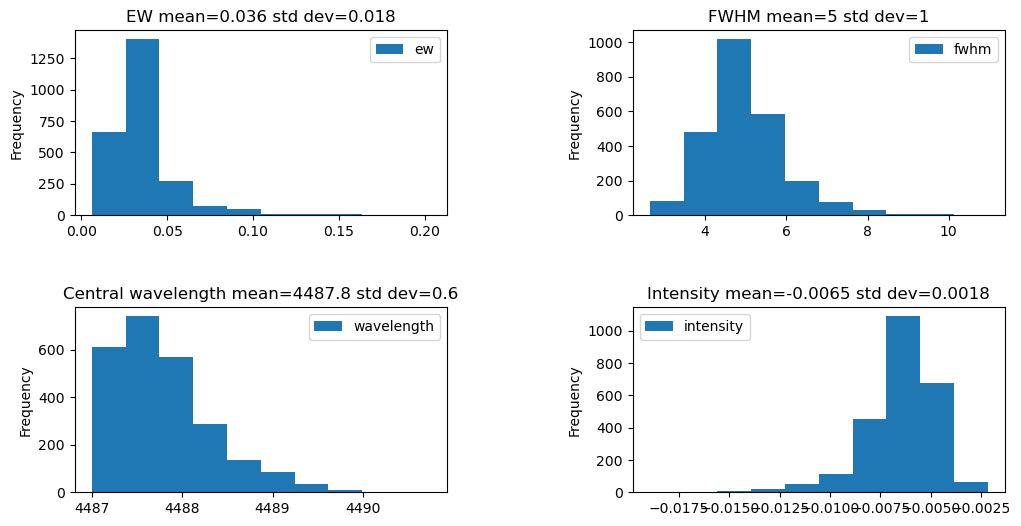

#### He I/Mg II 4471-81 re-fit with best parameters

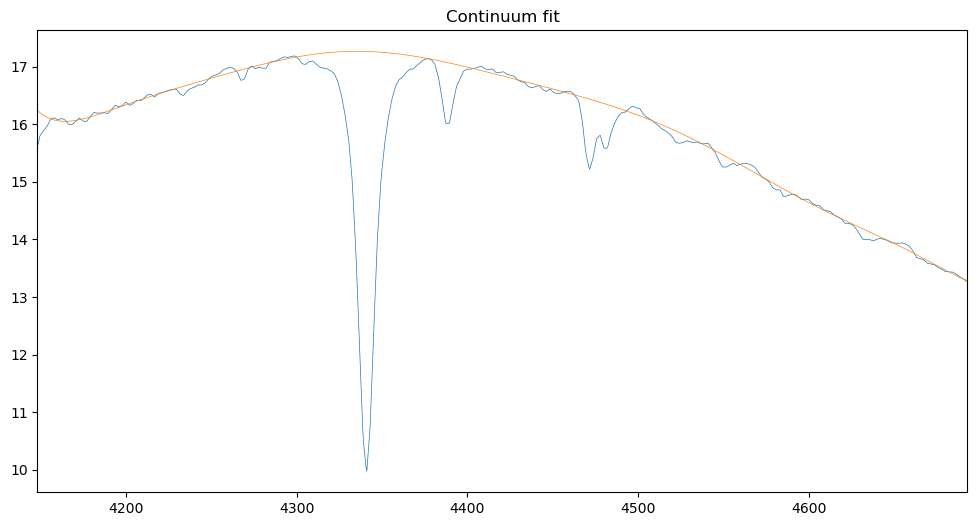

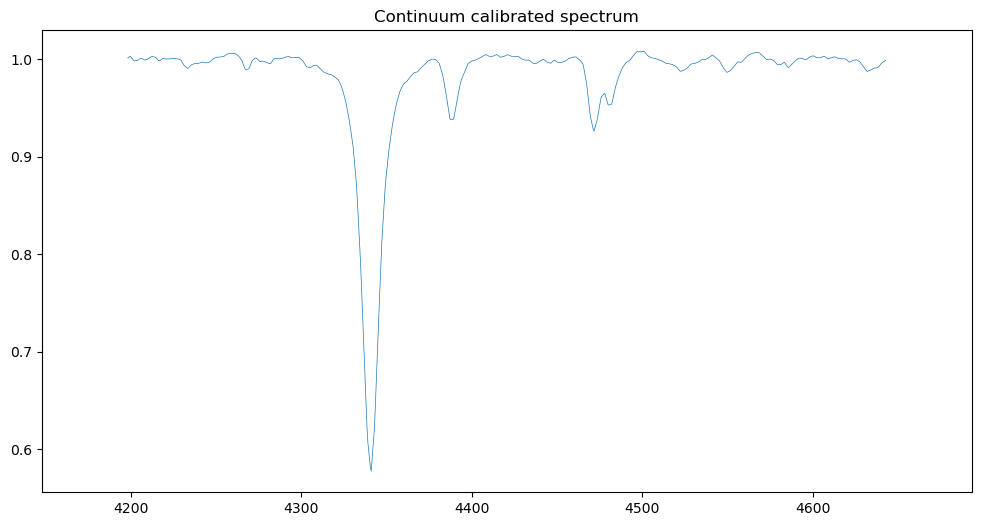

He I 4471 (gauss)
amp = -0.07226974373833189 
mu = 4471.612047463948 
sigma = 3.0055495480784713 
offset = 1.0 
chi2 = 0.0013298859046369368


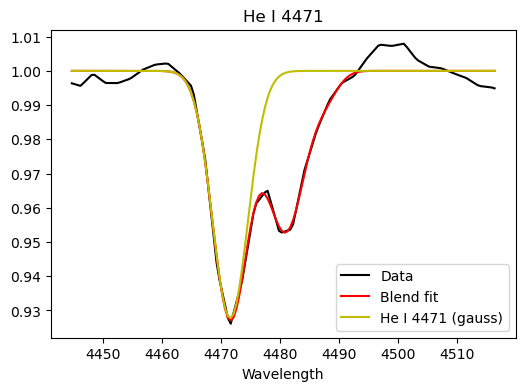

Mg II 4481 (gauss)
amp = -0.04663148103078145 
mu = 4481.006791102335 
sigma = 3.1941468327687996 
offset = 1.0 
chi2 = 0.0013298859046369368


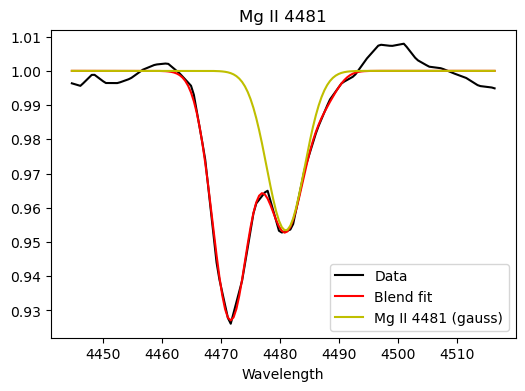

Unknown 4490 (gauss)
amp = -0.0064267650001901475 
mu = 4487.777304030457 
sigma = 2.2099305904312216 
offset = 1.0 
chi2 = 0.0013298859046369368


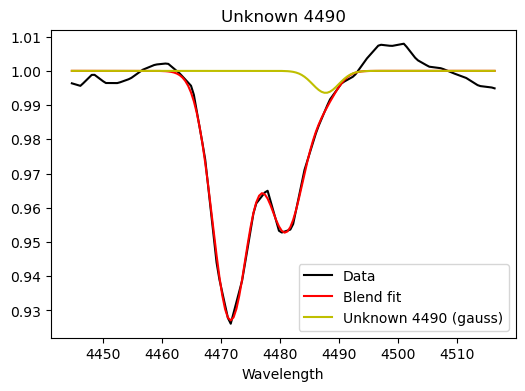

### Measuring He I 4713

Blended lines= [{'name': 'O II 4705', 'wavelength': 4705.0}, {'name': 'He I 4713', 'wavelength': 4713.0}]


#### He I 4713 preliminary fit

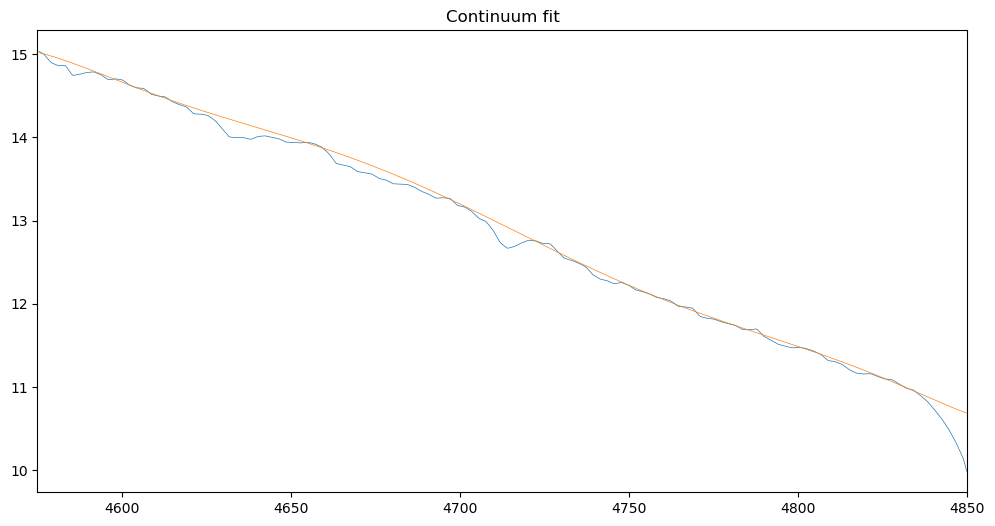

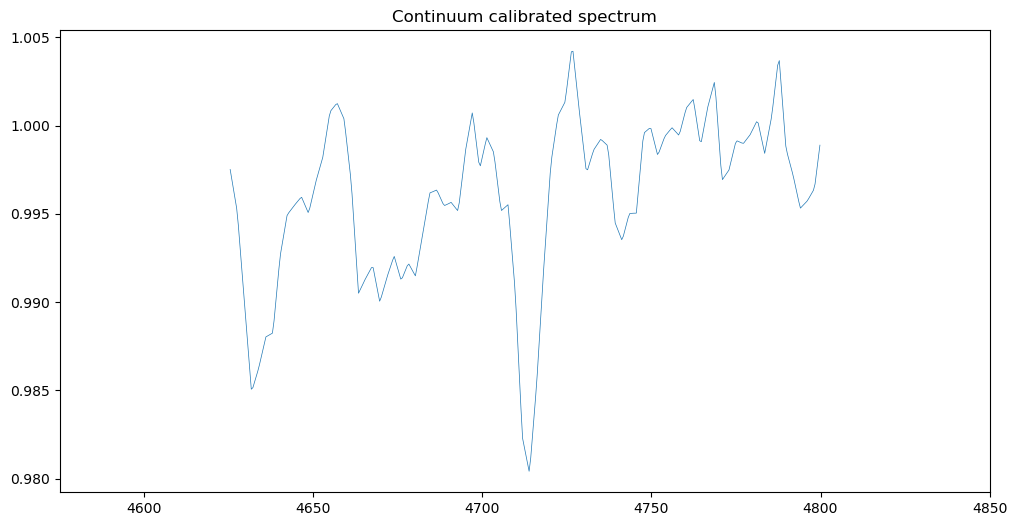

Fit window = (4638.6, 4779.4)
O II 4705 (gauss)
amp = -0.0031404798117084416 
mu = 4702.000000000001 
sigma = 9.401773448232795 
offset = 1.0 
chi2 = 0.0048830945363945


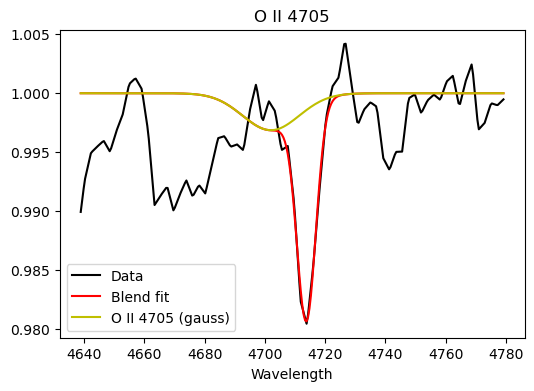

He I 4713 (gauss)
amp = -0.017950314359772644 
mu = 4713.782775621231 
sigma = 3.1282464791384355 
offset = 1.0 
chi2 = 0.0048830945363945


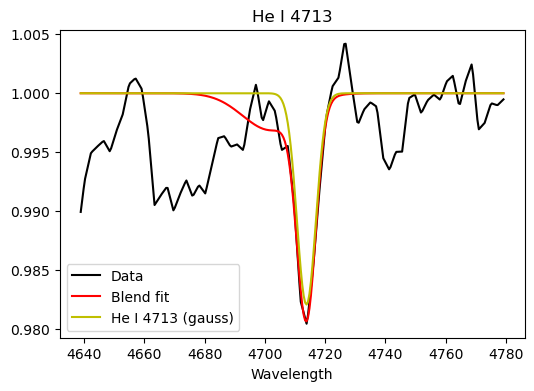

#### He I 4713 optimization

#### Plotting results for O II 4705

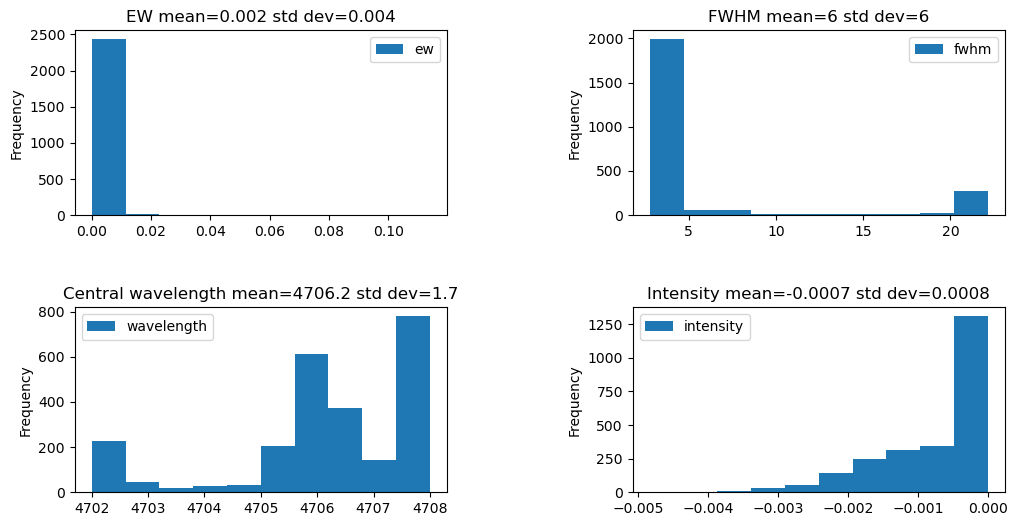

#### Plotting results for He I 4713

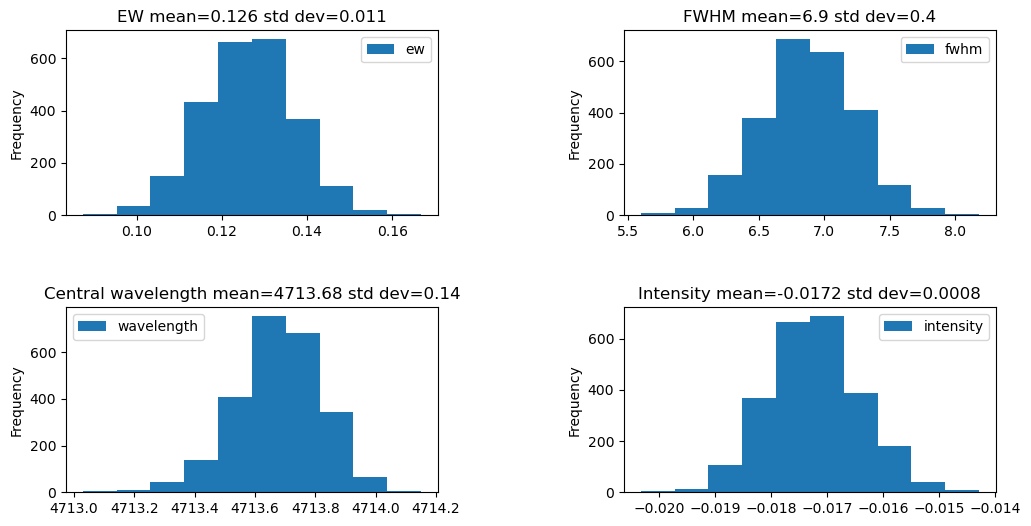

#### He I 4713 re-fit with best parameters

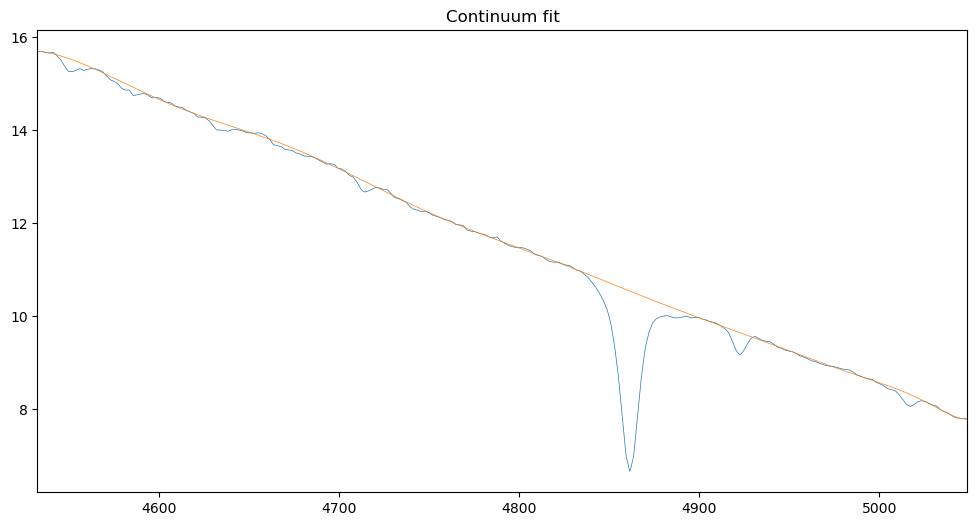

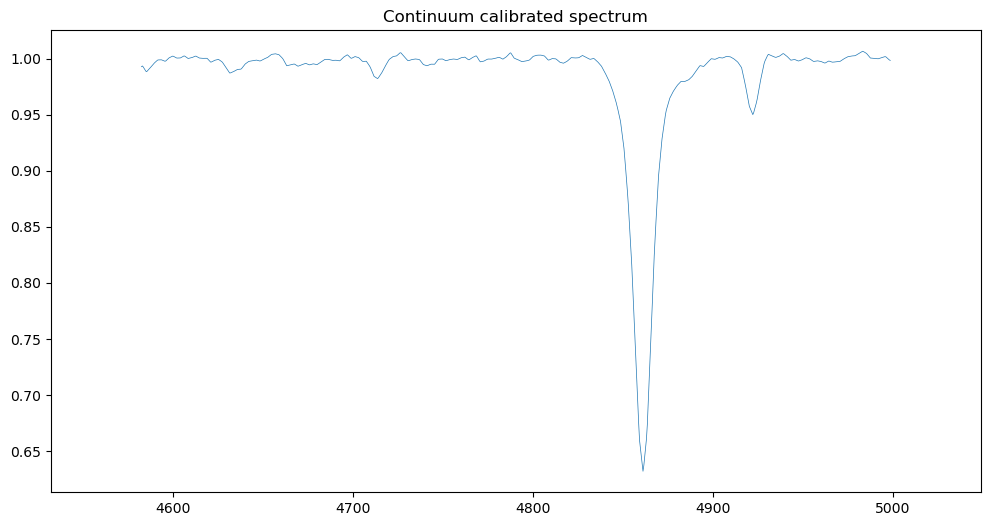

O II 4705 (gauss)
amp = -0.0016105860712082828 
mu = 4705.874108601358 
sigma = 1.1752216810290999 
offset = 1.0 
chi2 = 0.002497834259773184


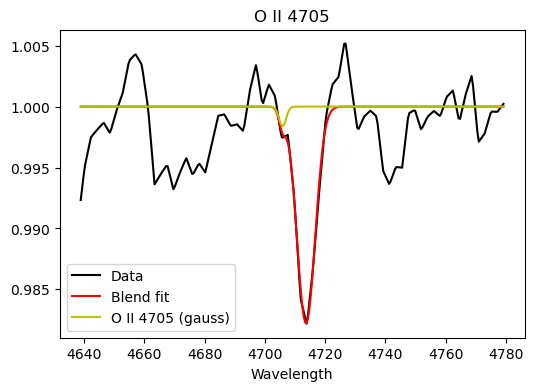

He I 4713 (gauss)
amp = -0.017797797711257144 
mu = 4713.647069356419 
sigma = 3.0229551942610864 
offset = 1.0 
chi2 = 0.002497834259773184


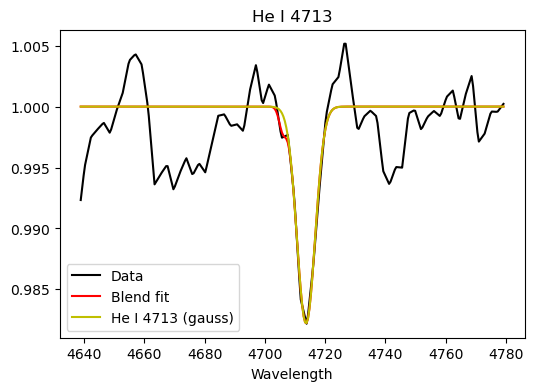

### Measuring H delta / He I 4121-4144

Blended lines= [{'name': 'H delta', 'wavelength': 4101.0, 'model': 'voigt'}, {'name': 'He I 4121', 'wavelength': 4121.0}, {'name': 'O II 4133', 'wavelength': 4133.0}, {'name': 'He I 4144', 'wavelength': 4144.0}]


#### H delta / He I 4121-4144 preliminary fit

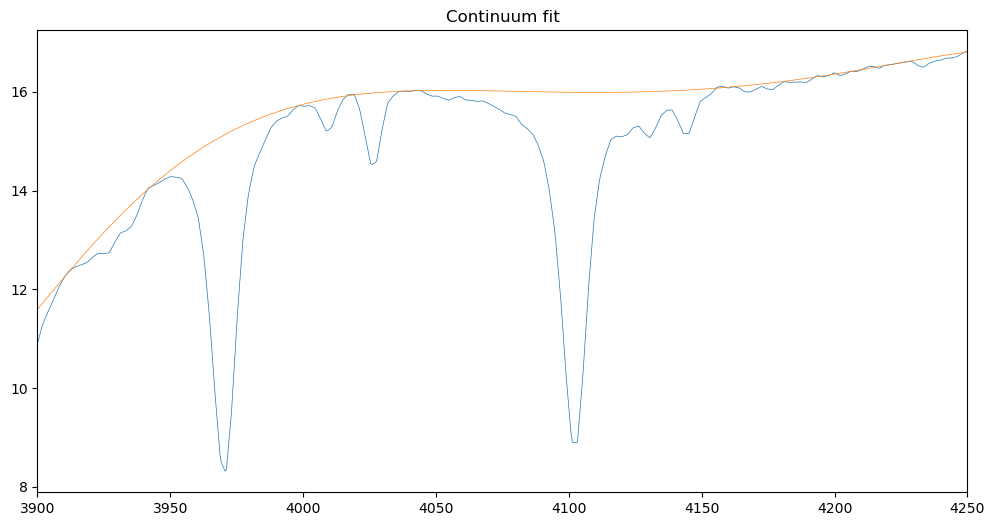

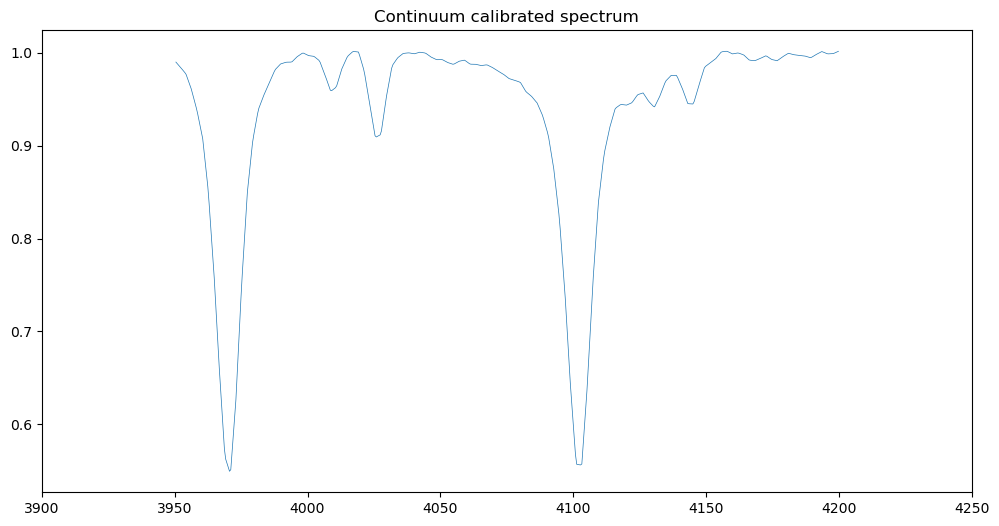

Fit window = (4047.2, 4197.8)
H delta (voigt)
amp = -8.16520986073998 
mu = 4101.997864859692 
sigma = 1.337701872137499 
gamma = 5.469962977294685 
offset = 1.0 
chi2 = 0.0046513484997837045


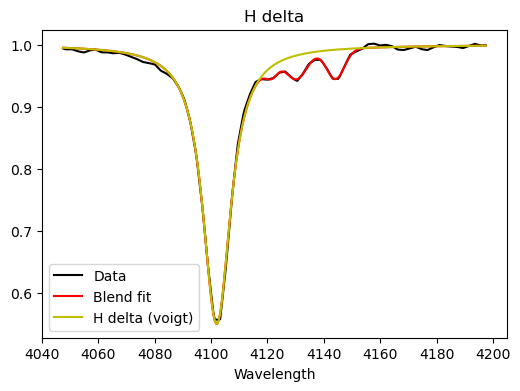

He I 4121 (gauss)
amp = -0.01865455203080901 
mu = 4121.575682495728 
sigma = 2.1132803795144284 
offset = 1.0 
chi2 = 0.0046513484997837045


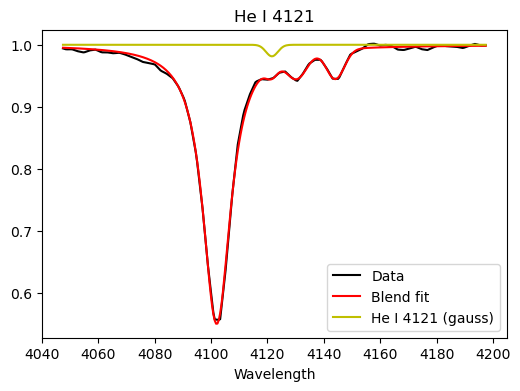

O II 4133 (gauss)
amp = -0.03851703829636155 
mu = 4130.4329293511755 
sigma = 3.6130868468126627 
offset = 1.0 
chi2 = 0.0046513484997837045


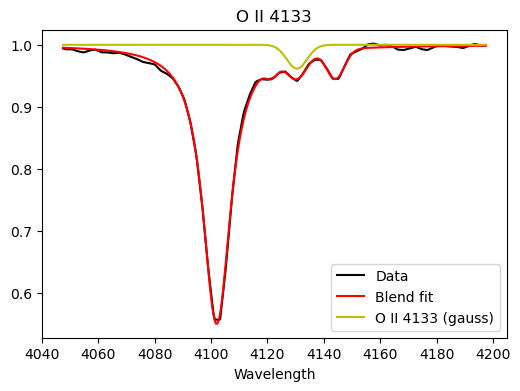

He I 4144 (gauss)
amp = -0.047507814183754035 
mu = 4144.102268499578 
sigma = 3.160458576773945 
offset = 1.0 
chi2 = 0.0046513484997837045


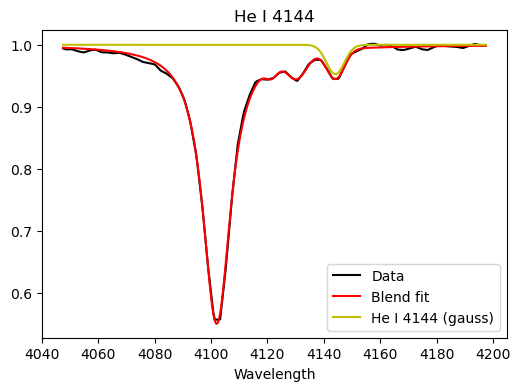

#### H delta / He I 4121-4144 optimization

#### Plotting results for H delta

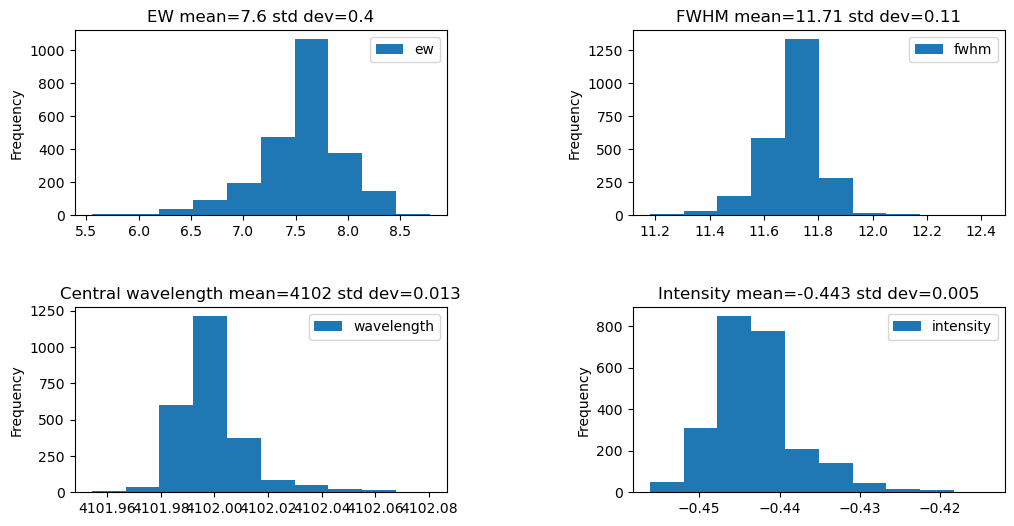

#### Plotting results for He I 4121

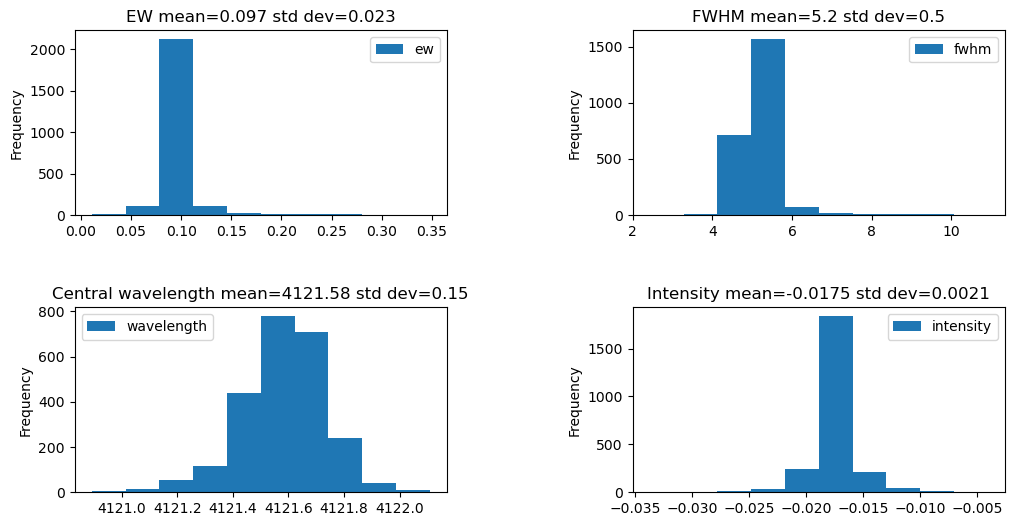

#### Plotting results for O II 4133

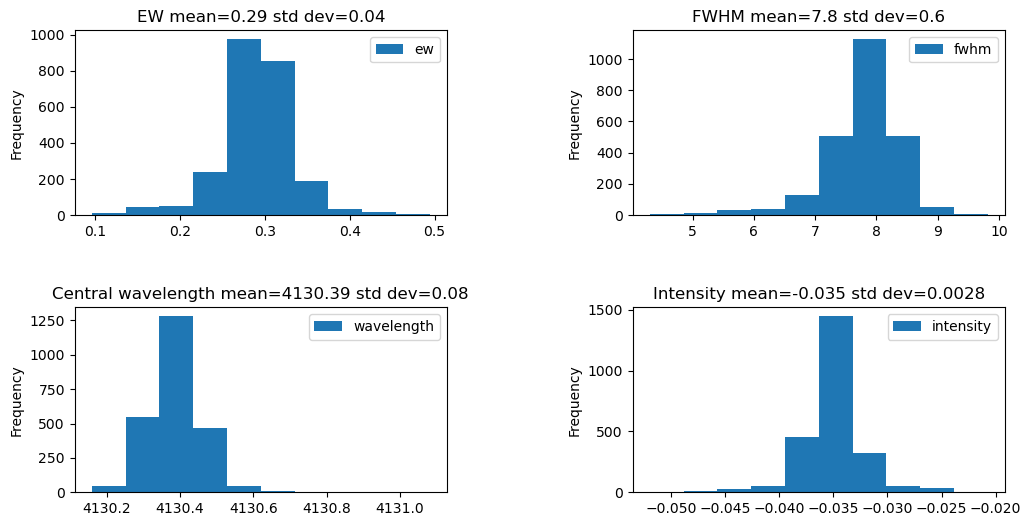

#### Plotting results for He I 4144

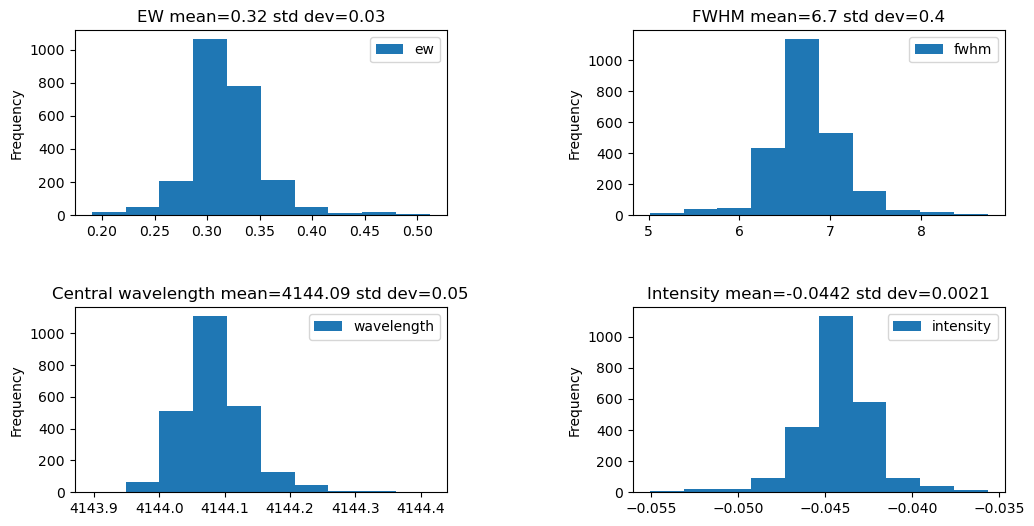

#### H delta / He I 4121-4144 re-fit with best parameters

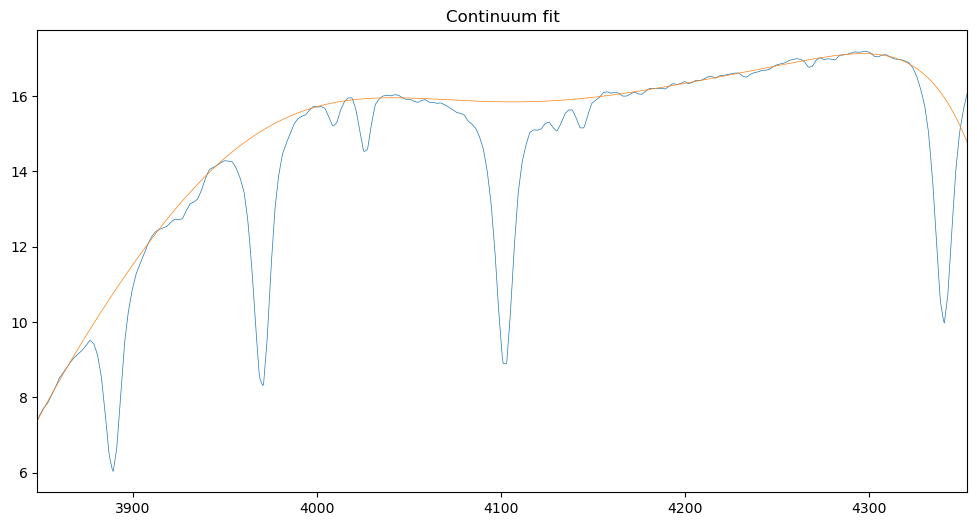

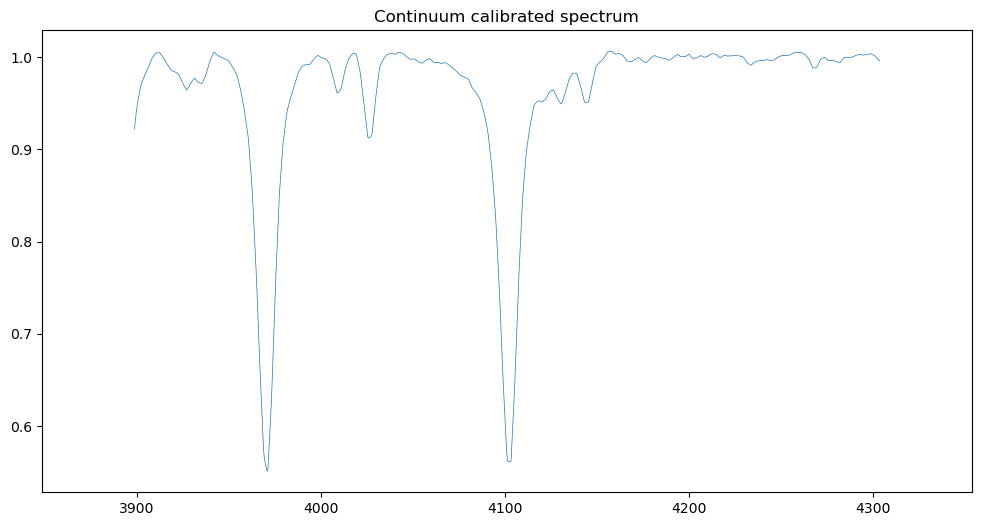

H delta (voigt)
amp = -7.561926870862605 
mu = 4101.999952900862 
sigma = 2.202209170763104 
gamma = 4.636633313587805 
offset = 1.0 
chi2 = 0.0036368266033613363


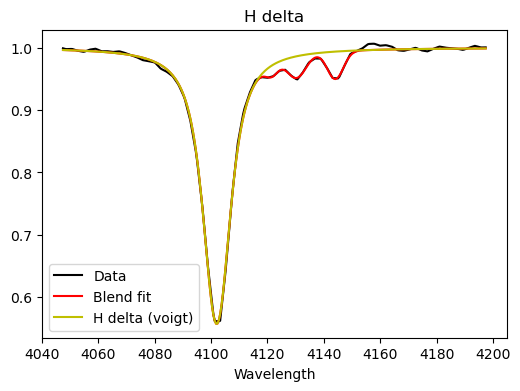

He I 4121 (gauss)
amp = -0.017641755603251017 
mu = 4121.5783124924055 
sigma = 2.1913213817094057 
offset = 1.0 
chi2 = 0.0036368266033613363


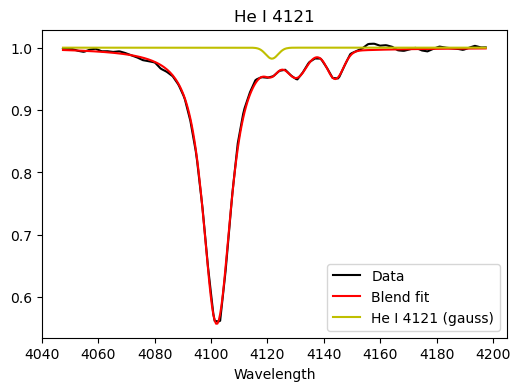

O II 4133 (gauss)
amp = -0.03487032074274492 
mu = 4130.3826348200655 
sigma = 3.315930819386525 
offset = 1.0 
chi2 = 0.0036368266033613363


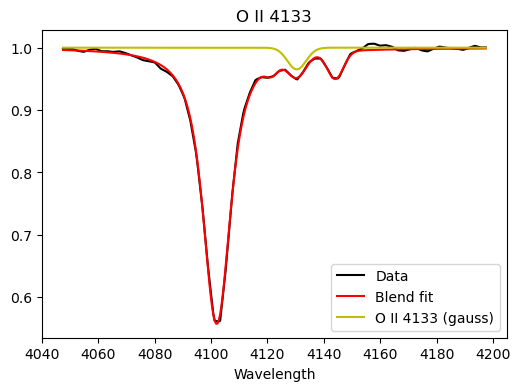

He I 4144 (gauss)
amp = -0.04405135303255286 
mu = 4144.07738971114 
sigma = 2.850544981528003 
offset = 1.0 
chi2 = 0.0036368266033613363


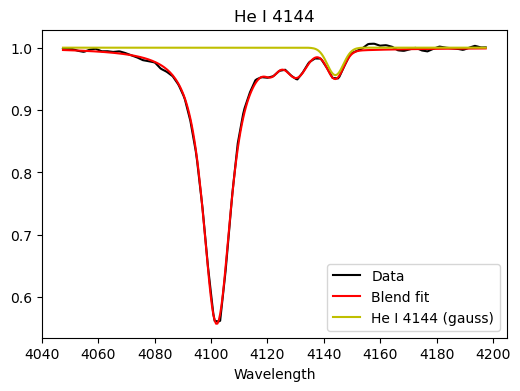

### Measuring He I 5016

Blended lines= [{'name': 'N II 5005', 'wavelength': 5005.0}, {'name': 'He I 5016', 'wavelength': 5016.0}, {'name': 'Unknown 5025', 'wavelength': 5025.0}, {'name': 'Unknown 5035', 'wavelength': 5035.0}, {'name': 'He I 5048', 'wavelength': 5048.0}, {'name': 'He I 5055', 'wavelength': 5055.0}]


#### He I 5016 preliminary fit

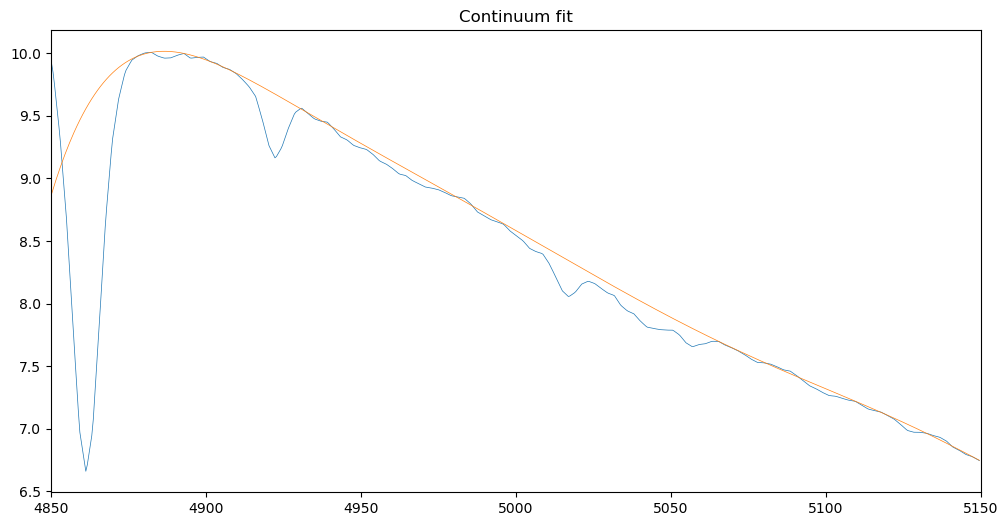

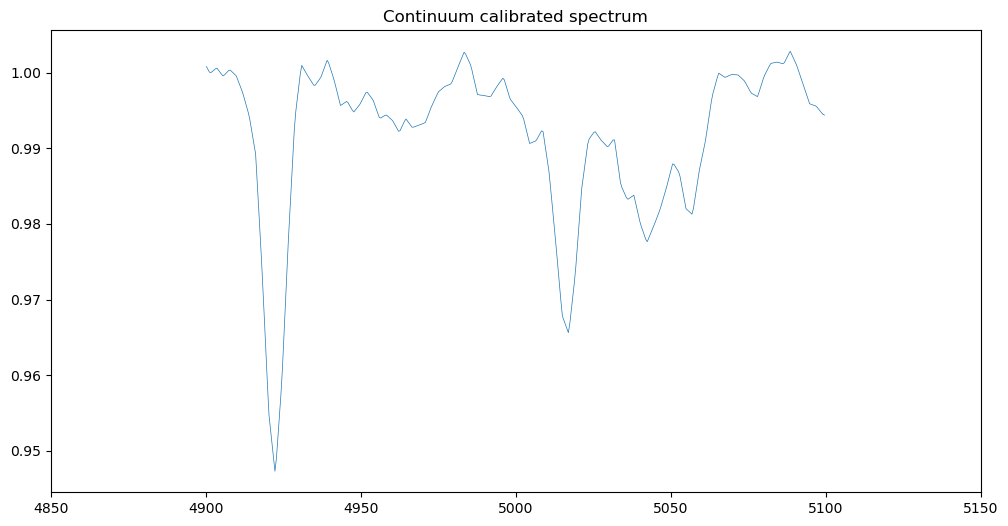

Fit window = (4942.5, 5100.0)
N II 5005 (gauss)
amp = -0.007756623459504245 
mu = 5007.999999999999 
sigma = 8.719168014835548 
offset = 1.0 
chi2 = 0.002661445431517034


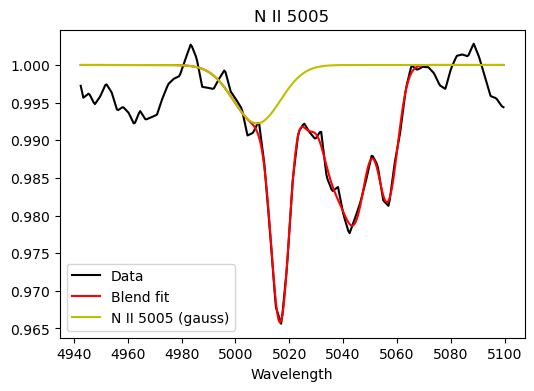

He I 5016 (gauss)
amp = -0.029484636087711687 
mu = 5016.769210627399 
sigma = 3.4067442225081868 
offset = 1.0 
chi2 = 0.002661445431517034


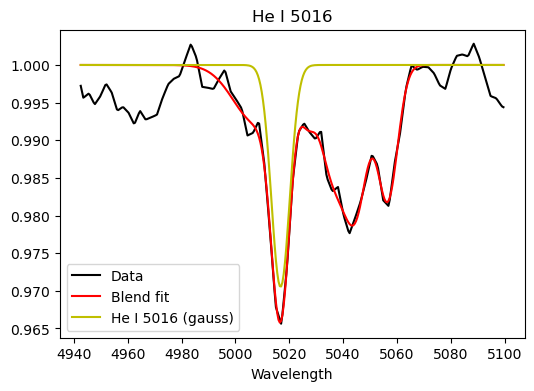

Unknown 5025 (gauss)
amp = -0.005073193109632655 
mu = 5026.577552194528 
sigma = 2.707171439673613 
offset = 1.0 
chi2 = 0.002661445431517034


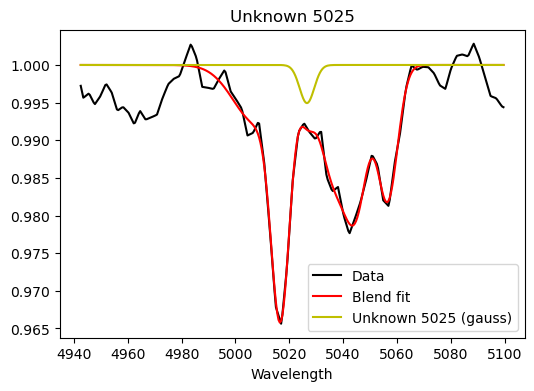

Unknown 5035 (gauss)
amp = -0.014152147329376452 
mu = 5036.284884600142 
sigma = 5.0730665601051586 
offset = 1.0 
chi2 = 0.002661445431517034


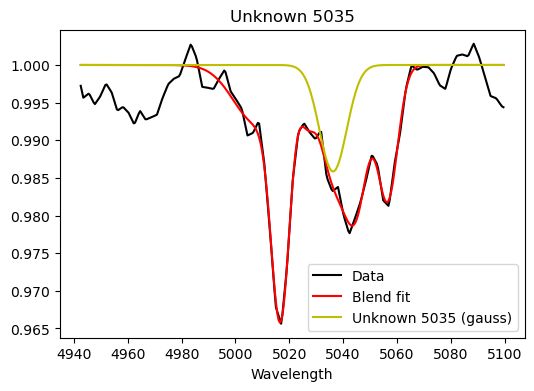

He I 5048 (gauss)
amp = -0.01719606606998015 
mu = 5045.000000000001 
sigma = 4.252018354531628 
offset = 1.0 
chi2 = 0.002661445431517034


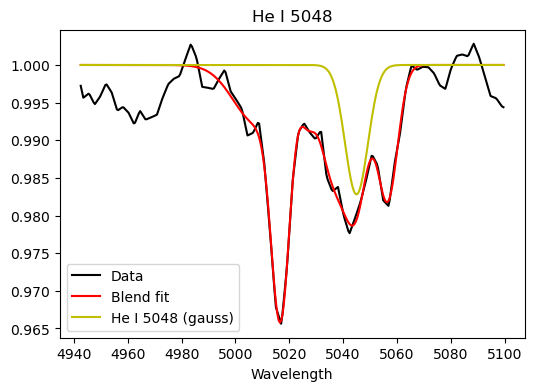

He I 5055 (gauss)
amp = -0.01777778412448796 
mu = 5056.549407396543 
sigma = 3.724448672292325 
offset = 1.0 
chi2 = 0.002661445431517034


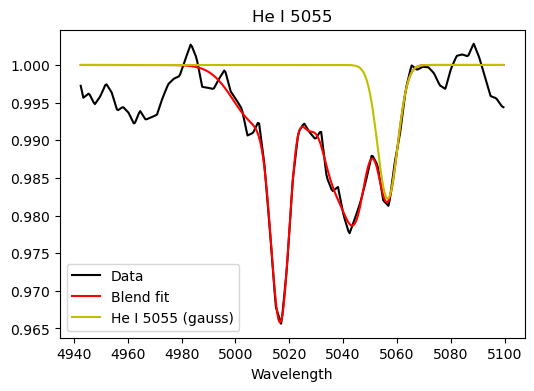

#### He I 5016 optimization

#### Plotting results for N II 5005

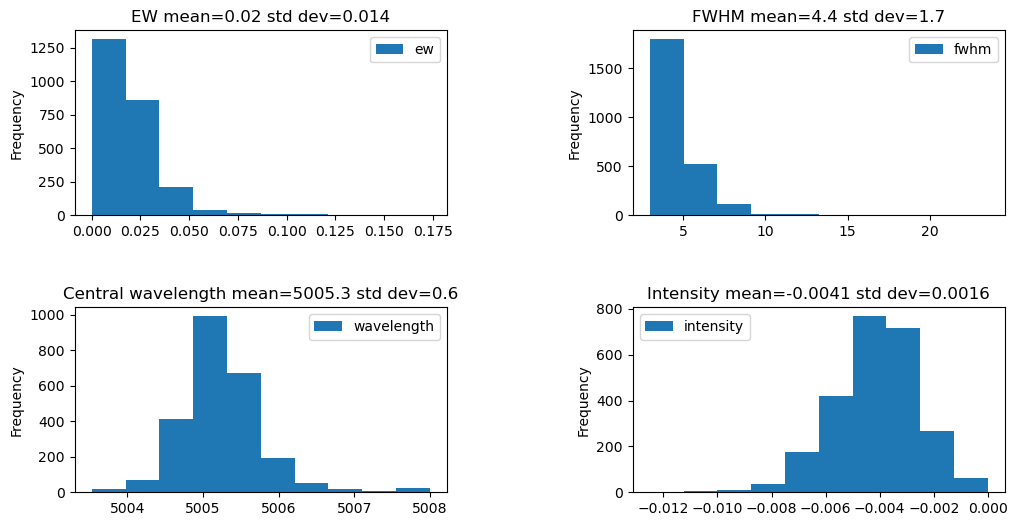

#### Plotting results for He I 5016

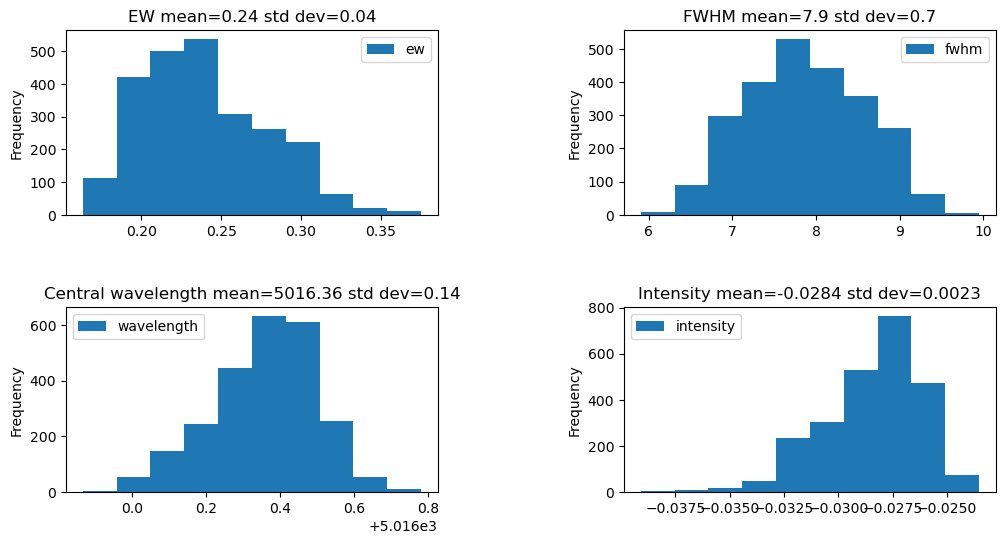

#### Plotting results for Unknown 5025

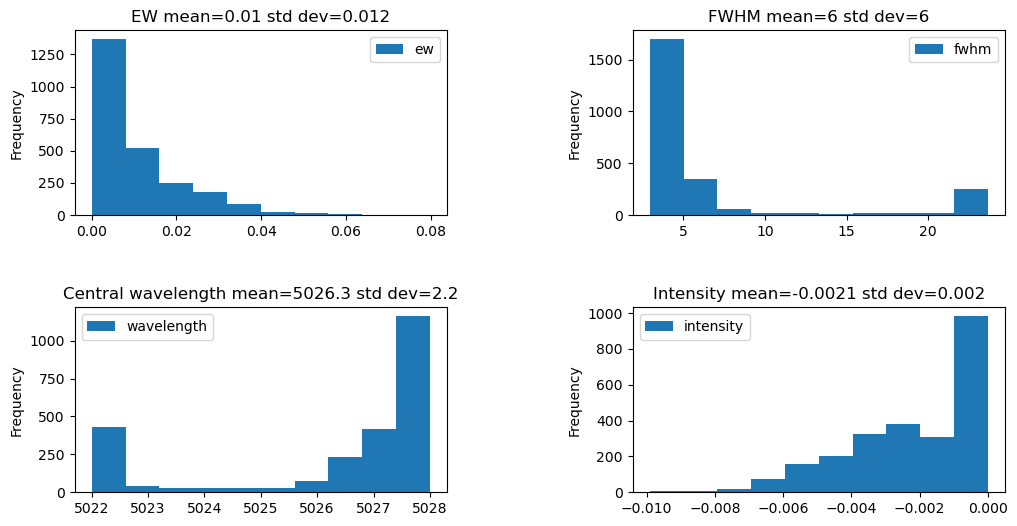

#### Plotting results for Unknown 5035

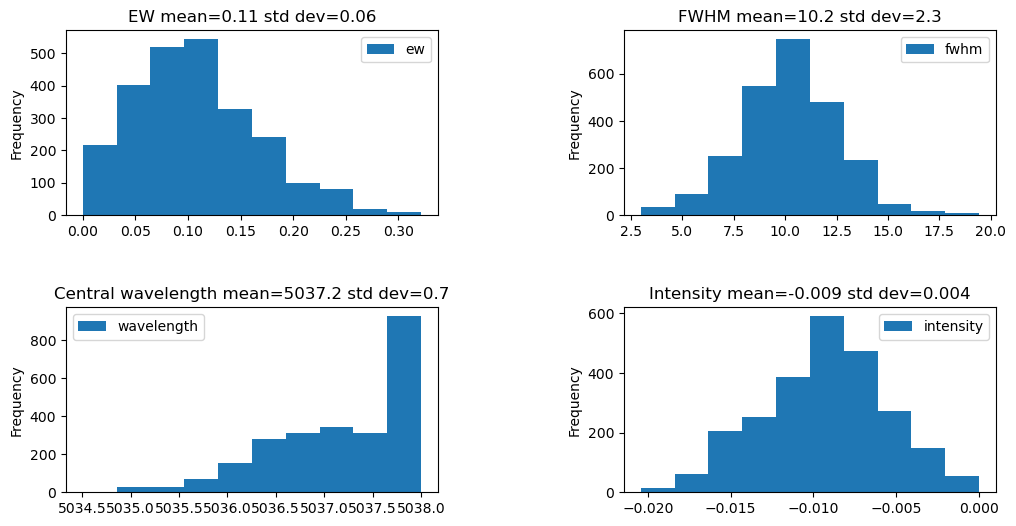

#### Plotting results for He I 5048

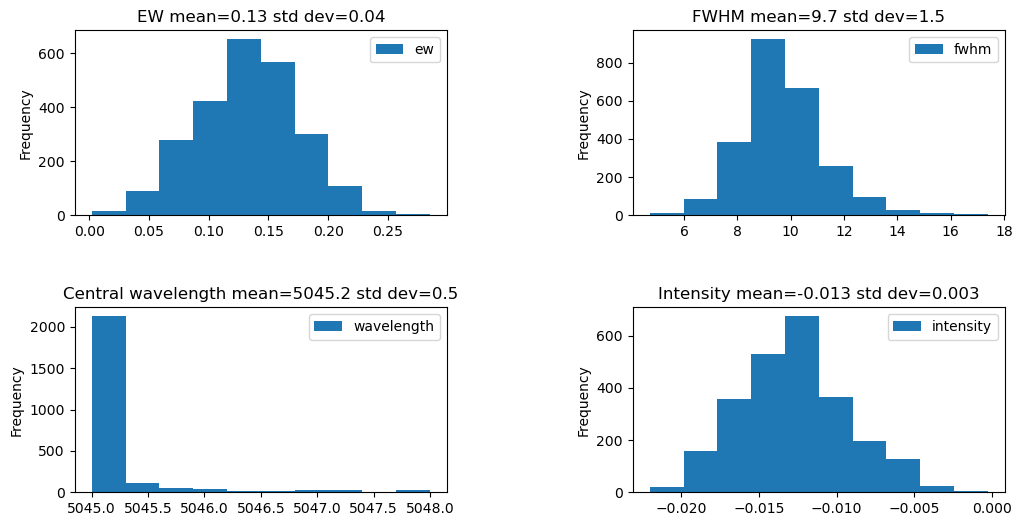

#### Plotting results for He I 5055

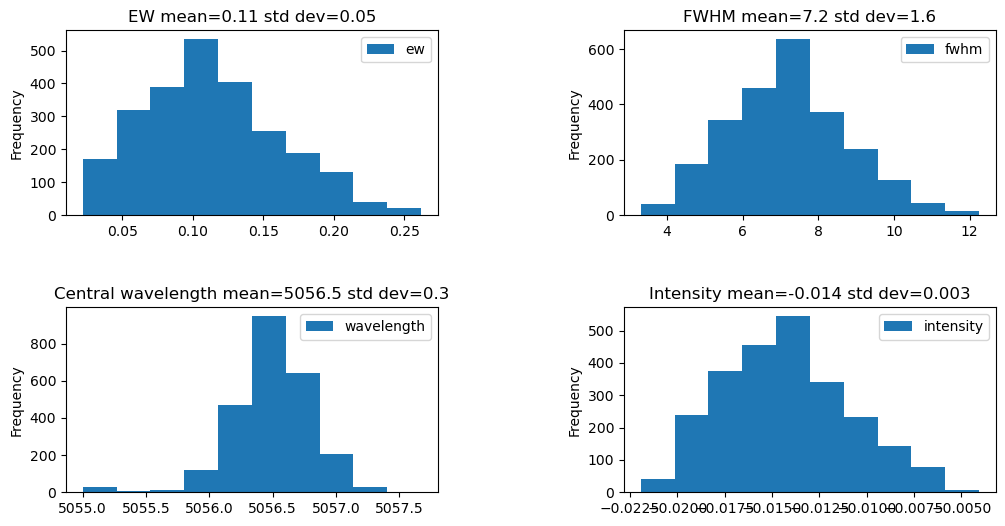

#### He I 5016 re-fit with best parameters

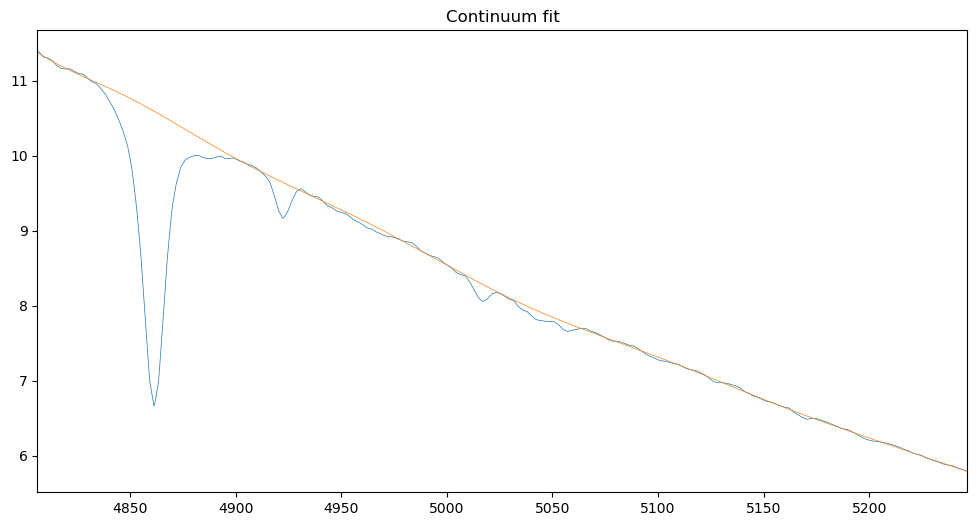

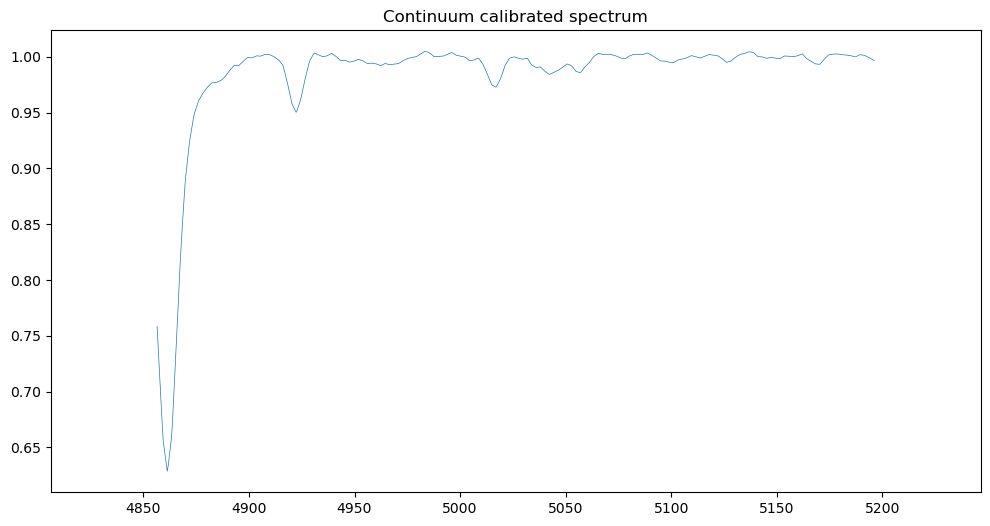

N II 5005 (gauss)
amp = -0.003570568123226553 
mu = 5005.18907072507 
sigma = 1.5036935898190453 
offset = 1.0 
chi2 = 0.0026459646798038115


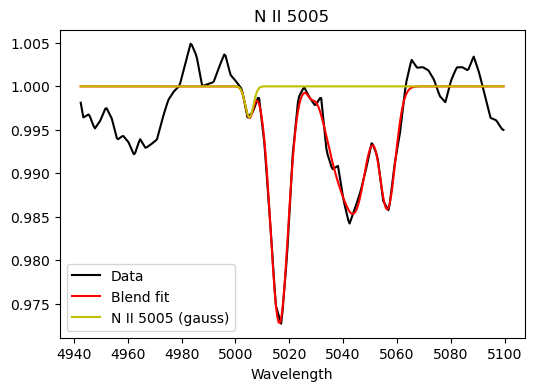

He I 5016 (gauss)
amp = -0.02722921562512386 
mu = 5016.334184842951 
sigma = 3.2481616815215757 
offset = 1.0 
chi2 = 0.0026459646798038115


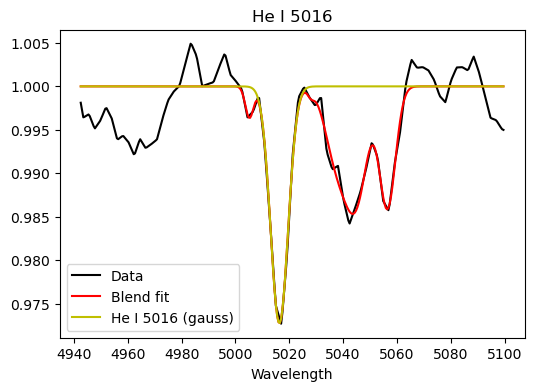

Unknown 5025 (gauss)
amp = -0.0008089236652485684 
mu = 5027.999999999999 
sigma = 1.255151742225553 
offset = 1.0 
chi2 = 0.0026459646798038115


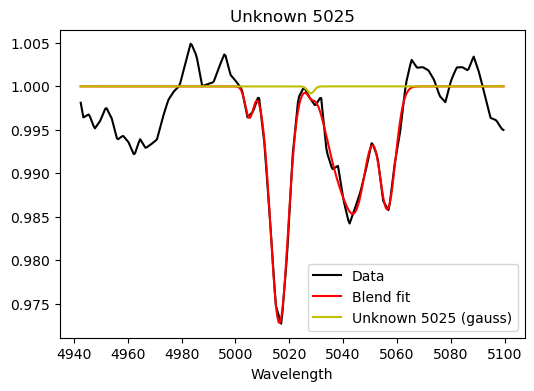

Unknown 5035 (gauss)
amp = -0.008142566951782672 
mu = 5037.6264618209425 
sigma = 4.243833672099648 
offset = 1.0 
chi2 = 0.0026459646798038115


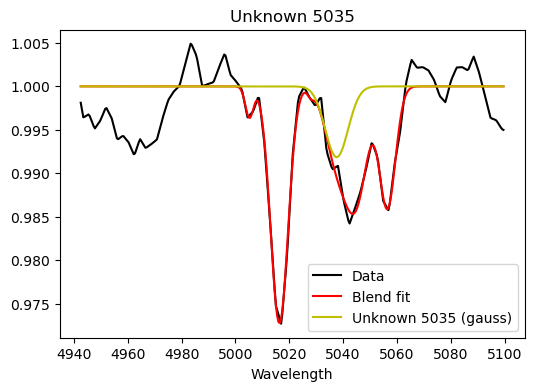

He I 5048 (gauss)
amp = -0.012352006305760173 
mu = 5045.000000000001 
sigma = 4.057082272363907 
offset = 1.0 
chi2 = 0.0026459646798038115


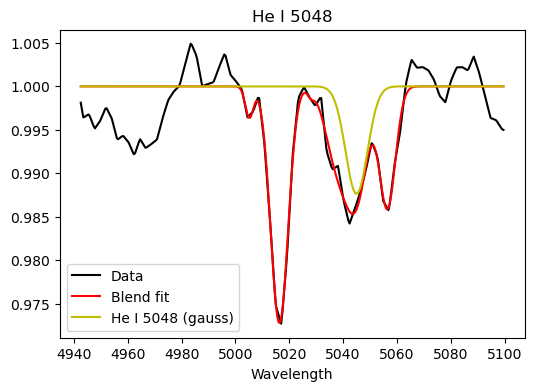

He I 5055 (gauss)
amp = -0.013903408923818576 
mu = 5056.483033307952 
sigma = 2.980845145587742 
offset = 1.0 
chi2 = 0.0026459646798038115


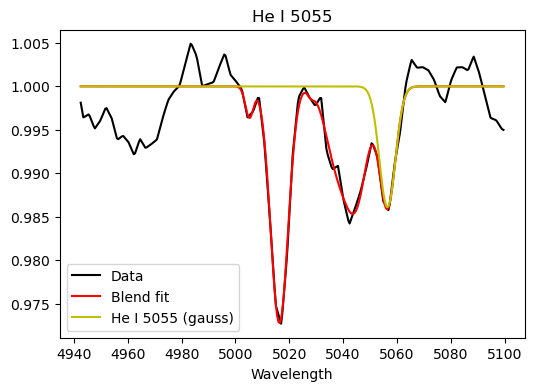

In [32]:
for measuring_blend in measuring_blends:
    results = measure_blend(wl, flux, measuring_blend, show_param_dependencies=SHOW_PARAM_DEPENDENCIES)
    summary_results = pd.concat([summary_results, results], axis=0)

## Summary Results

In [33]:
summary_results = summary_results.sort_values(by=["wavelength"], ascending=False)

summary_results


,line_name,wavelength,delta_wavelength,ew,delta_ew,fwhm,delta_fwhm,intensity,delta_intensity
7,He I 6678,6677.71862,0.354431,0.248354,0.061697,9.647175,1.991251,-0.024081,0.002424
0,H alfa,6562.761985,0.071954,5.276336,0.552737,14.439769,0.399308,-0.256667,0.006822
5,He I 5055,5056.492255,0.312018,0.11409,0.047817,7.189074,1.551951,-0.014269,0.003304
4,He I 5048,5045.170434,0.50897,0.132216,0.042057,9.701215,1.528224,-0.012735,0.003457
3,Unknown 5035,5037.200672,0.730431,0.1075,0.058723,10.201467,2.336637,-0.00928,0.003715
2,Unknown 5025,5026.309999,2.191317,0.009782,0.011638,6.43919,6.384483,-0.002056,0.002014
1,He I 5016,5016.359324,0.140349,0.239606,0.038934,7.875213,0.70107,-0.02842,0.002268
0,N II 5005,5005.260113,0.557411,0.020232,0.014152,4.357278,1.658523,-0.004137,0.001567
6,He I 4922,4922.120933,0.054918,0.396998,0.019981,7.603108,0.252562,-0.049033,0.001028
1,H beta,4861.240892,0.013663,6.184946,0.107356,12.567409,0.029086,-0.363153,0.001517


In [34]:
summary_results.to_csv("line_measured_adid_borealis_20251209.csv")